# Operational certification of nonclassicality in arbitrary quantum states from few-copies: reproduction notebook

This notebook reproduces every number, table and figure of the Letter and its Supplemental Material (SM). It is self-contained: all functions are defined below, and no external data files are needed.

**Conventions.** Quadratures $\hat x=(a+a^\dagger)/\sqrt2$, $\hat p=(a-a^\dagger)/(\sqrt2 i)$, $\hbar=1$, so that the vacuum has $W=e^{-x^2-p^2}/\pi$ and $\int W\,dx\,dp=1$. The Wigner moments are $w_n=\int W^n\,dx\,dp$, and the parity biases measured by the interferometer of Theorem 1 are $s_n=n\pi^{n-1}w_n$.

**Running.** Set `QUICK = True` in the first code cell for a fast end-to-end check (about 15 minutes) with fewer repetitions and lower orders. With `QUICK = False` the notebook reproduces the published numbers (a few hours on two cores). Results are written to `data/` as JSON and figures to `figs/` as PDF.

| Section | Result in the paper |
|---|---|
| 1 | Core functions: Wigner kernel, exact moments, example states |
| 2 | Theorem 1 verified with an explicit interferometer (SM C) |
| 3 | Table I and Fig. 1(a): exact thresholds for the mixed Fock state (SM D) |
| 4 | Fig. 1(b): Hankel thresholds for the noisy cat state (SM D) |
| 5 | Fig. 3 (End Matter II): random Hilbert-Schmidt states |
| 6 | Gaussian states, the monotone $\mathcal M_4$, readout errors and loss (SM E, G) |
| 7 | Fig. 2(c), SM G: finite-copy certificates and false-certification rates |
| 8 | Fig. 2(a, b), SM H: interferometer, tomography and Haar shadows for $\rho_{0.2}$ and a noisy odd cat with $\alpha=1$; $\alpha=4$ for the SM table |
| 9 | SM G: non-adaptive displaced-parity search versus unknown displacement |
| 9b | Fig. 2(d), End Matter III, SM G: calibrated and model-free adaptive strategies versus the moment certificate |
| 9c | Fig. 2(a, b), Fig. 4, SM H: unbiased homodyne tomography (simulation and leading-order bound) |
| 10 | Fig. 4 (End Matter III), SM H: energy scaling |
| 11 | SM G: Fock states |
| 12 | SM G: imperfect mode overlap; End Matter III: heralded sources |
| 12b | SM G: detector efficiency |
| 13 | SM H: Haar-shadow certification cost versus truncation |
| 14 | SM I: comparison with Fock-fidelity witnesses and Bochner certificates |
| 15 | SM E: N00N and photon-added coherent states |
| 16 | Figures of the paper |

### Installation
The next cell installs the required packages (NumPy, SciPy, mpmath, QuTiP, Matplotlib) into the Python that runs this notebook. It is needed only once per computer, and packages that are already installed are left as they are.

In [4]:
%pip install -q numpy scipy mpmath "qutip>=5" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
QUICK = False   # True: fast check with fewer repetitions; False: published numbers
import os, json, math, itertools, time, warnings
import numpy as np, mpmath as mp, qutip as qt
import matplotlib as mpl, matplotlib.pyplot as plt
from numpy.polynomial.hermite import hermgauss
from scipy.special import eval_genlaguerre, gammaln, eval_laguerre
from scipy.linalg import expm, logm
from scipy.integrate import simpson
from scipy.stats import binom
from scipy.interpolate import RegularGridInterpolator
os.makedirs('data', exist_ok=True); os.makedirs('figs', exist_ok=True)
T = lambda full, quick: quick if QUICK else full
DELTA, POWER = 0.05, 0.9           # confidence 1-delta and power of all certificates
def save(name, obj): json.dump(obj, open(f'data/{name}.json','w'), indent=1, default=float)
t_start = time.time()

In [6]:
# plot style: Times-like serif font as in the manuscript, readable sizes, grids
from matplotlib import font_manager
for f in font_manager.findSystemFonts():
    if 'texgyretermes' in f.lower(): font_manager.fontManager.addfont(f)
mpl.rcParams.update({'font.family':'serif','font.serif':['TeX Gyre Termes','Times New Roman','STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':9,'axes.labelsize':10,'legend.fontsize':7.5,'xtick.labelsize':8.5,'ytick.labelsize':8.5,
    'axes.linewidth':0.8,'pdf.fonttype':42})
COL = dict(blue='#1f4fd1', orange='#e8590c', green='#2ca02c', purple='#7b2cbf', red='#d62728', yellow='#d4a000', cyan='#17becf')

## 1. Core functions

The Wigner function of a state supported on $d$ Fock levels is $W(x,p)=e^{-(x^2+p^2)}\,\mathrm{Tr}[\rho B(x,p)]$ with a polynomial matrix $B$. Hence $W^n$ is a polynomial times $e^{-n(x^2+p^2)}$, and Gauss-Hermite quadrature of order $\geq n(d-1)+1$ per axis integrates it exactly. For the noisy cat state, $W$ is a finite sum of Gaussians with linear phases, so every moment is an exact finite sum of Gaussian integrals.

In [8]:
def wigner_poly_kernel(d, x, p):
    # B(x,p) with W(x,p)=exp(-(x^2+p^2)) Tr[rho B(x,p)], vectorised over points
    x=np.atleast_1d(x); p=np.atleast_1d(p); z=x+1j*p; r2=x*x+p*p
    B=np.zeros((len(x),d,d),dtype=complex)
    for n in range(d):
        for m in range(n,d):
            k=m-n; pref=((-1)**n)/np.pi*np.exp(0.5*(gammaln(n+1)-gammaln(m+1)))
            val=pref*(math.sqrt(2.0)*z)**k*eval_genlaguerre(n,k,2.0*r2)
            B[:,m,n]=val; B[:,n,m]=np.conj(val)
    return B

def wigner_grid(rho, x, p):
    d=rho.shape[0]; X,P=np.meshgrid(x,p,indexing='ij')
    B=wigner_poly_kernel(d,X.ravel(),P.ravel())
    return (np.real(np.einsum('ij,qji->q',rho,B))*np.exp(-(X.ravel()**2+P.ravel()**2))).reshape(X.shape)

_GH={}
def exact_moment(rho, n, chunk=4000):
    # w_n = int W^n dx dp, exact by Gauss-Hermite quadrature (kernels cached only for small d)
    d=rho.shape[0]
    if n==1: return float(np.real(np.trace(rho)))
    K=n*(d-1)+2; u,wt=hermgauss(K); U,V=np.meshgrid(u,u,indexing='ij'); U=U.ravel()/math.sqrt(n); V=V.ravel()/math.sqrt(n); Wt=np.outer(wt,wt).ravel()/n
    if d<=12:
        if (d,n) not in _GH: _GH[(d,n)]=wigner_poly_kernel(d,U,V)
        return float(np.dot(Wt, np.real(np.einsum('ij,qji->q',rho,_GH[(d,n)]))**n))
    tot=0.0
    for a in range(0,len(U),chunk):
        B=wigner_poly_kernel(d,U[a:a+chunk],V[a:a+chunk]); tot+=np.dot(Wt[a:a+chunk],np.real(np.einsum('ij,qji->q',rho,B))**n)
    return float(tot)

def moments(rho, M):
    return np.array([np.nan]+[exact_moment(rho,n) for n in range(1,M+1)])

def svals(rho, M=5):
    w=moments(rho,M); return {k:float(np.clip(k*math.pi**(k-1)*w[k],-1,1)) for k in range(2,M+1)}

def log_negativity(rho, npts=801):
    d=rho.shape[0]; L=math.sqrt(2*d+1)+5; x=np.linspace(-L,L,npts); W=wigner_grid(rho,x,x)
    return math.log(np.sum(np.abs(W))*(x[1]-x[0])**2)

def L4_of(rho):
    w=moments(rho,4); return 0.5*math.log(w[2]**3/w[4])

# ----- example states -----
def fock_dm(n,d=None):
    d=d or n+2; r=np.zeros((d,d),complex); r[n,n]=1; return r
def mixed_fock(lam=0.2,d=3):
    r=np.zeros((d,d),complex); r[0,0]=lam; r[1,1]=1-lam; return r
def coherent_vec(alpha,d):
    return np.exp(-abs(alpha)**2/2)*np.array([alpha**k/math.sqrt(math.factorial(k)) for k in range(d)],dtype=complex)
def cat_dm(alpha,d,parity=-1,lam=0.0):
    a=coherent_vec(alpha,d); b=coherent_vec(-alpha,d); c=a+parity*b; c/=np.linalg.norm(c)
    rcl=0.5*(np.outer(a,a.conj())/np.vdot(a,a)+np.outer(b,b.conj())/np.vdot(b,b))
    return (1-lam)*np.outer(c,c.conj())+lam*rcl

def cat_moments_mp(alpha, lam, parity, M, dps=80):
    # exact moments of (1-lam)|cat><cat| + lam rho_cl, alpha real, high precision
    mp.mp.dps=dps; alpha=mp.mpf(alpha); lam=mp.mpf(lam)
    X=mp.sqrt(2)*alpha; K=2*mp.sqrt(2)*alpha; N2=2*(1+parity*mp.e**(-2*alpha**2))
    c1=(1-lam)/(mp.pi*N2)+lam/(2*mp.pi); c3=parity*(1-lam)/(mp.pi*N2)
    out=[None]
    for n in range(1,M+1):
        s=mp.mpf(0)
        for n1 in range(n+1):
            for n2 in range(n-n1+1):
                for n3 in range(n-n1-n2+1):
                    n4=n-n1-n2-n3
                    mult=mp.factorial(n)/(mp.factorial(n1)*mp.factorial(n2)*mp.factorial(n3)*mp.factorial(n4))
                    A=X*(n1-n2); Bq=X*X*(n1+n2); Cc=K*(n3-n4)
                    s+=mult*c1**(n1+n2)*c3**(n3+n4)*(mp.pi/n)*mp.e**(A*A/n-Bq-Cc*Cc/(4*n))
        out.append(s)
    return out

# ----- checks against QuTiP -----
rho=np.array(qt.rand_dm(8,seed=3).full()); x=np.linspace(-3,3,21)
print('Wigner kernel vs QuTiP, max deviation:', np.abs(wigner_grid(rho,x,x)-qt.wigner(qt.Qobj(rho),x,x).T).max())
c=cat_moments_mp(2.0,0.3,-1,5); print('cat moments exact vs Fock basis:', [float(c[k]) for k in (2,3,5)], moments(cat_dm(2.0,40,-1,0.3),5)[[2,3,5]])

Wigner kernel vs QuTiP, max deviation: 1.0408340855860843e-16
cat moments exact vs Fock basis: [0.11855922139699065, 0.007953135874802236, 8.61474083706472e-05] [1.18559221e-01 7.95313587e-03 8.61474084e-05]


## 2. Theorem 1 with an explicit interferometer (SM C)

We build $F_n$ (Helmert matrix, determinant one) as the passive unitary $U_F=\exp(\sum_{jk}A_{jk}a_j^\dagger a_k)$ with $F_n=e^{A}$, apply it to $\rho^{\otimes n}$ in Fock space, and compare the parity of the relative modes with $n\pi^{n-1}w_n$. For states with at most $M$ photons per copy, a cutoff of $nM$ photons per mode is exact because $U_F$ conserves the total photon number.

In [10]:
def Fmat(n):
    F=np.zeros((n,n)); F[0]=1/math.sqrt(n)
    for k in range(1,n): F[k,:k]=1; F[k,k]=-k; F[k]/=math.sqrt(k*(k+1))
    if np.linalg.det(F)<0: F[1]*=-1
    return F
def mode_ops(nmodes,D):
    a=np.diag(np.sqrt(np.arange(1,D)),1); I=np.eye(D); ops=[]
    for k in range(nmodes):
        mats=[I]*nmodes; mats[k]=a; M=mats[0]
        for m in mats[1:]: M=np.kron(M,m)
        ops.append(M)
    return ops
def parity_expectation(rho,n):
    d=rho.shape[0]; D=n*(d-1)+1; a=mode_ops(n,D); A=np.real(logm(Fmat(n))); A=(A-A.T)/2
    U=expm(sum(A[j,k]*a[j].conj().T@a[k] for j in range(n) for k in range(n)))
    r=np.zeros((D,D),complex); r[:d,:d]=rho; R=r
    for _ in range(n-1): R=np.kron(R,r)
    par=np.diag((-1.0)**np.arange(D)); Op=np.eye(D)
    for _ in range(n-1): Op=np.kron(Op,par)
    return float(np.real(np.trace(U@R@U.conj().T@Op)))
rng=np.random.default_rng(7); rows=[]
states=[('mixed Fock, lambda=0.2',mixed_fock(0.2,2))]
for k in range(2):
    G=rng.normal(size=(3,3))+1j*rng.normal(size=(3,3)); r=G@G.conj().T; states.append((f'random state #{k}',r/np.trace(r)))
for name,r in states:
    for n in T([2,3,4],[2,3]):
        s=parity_expectation(r,n); w=exact_moment(r,n)
        rows.append(dict(state=name,n=n,parity=s,moment=n*math.pi**(n-1)*w))
        print(f'{name:24s} n={n}: parity {s:.12f}   n pi^(n-1) w_n {n*math.pi**(n-1)*w:.12f}   |diff| {abs(s-n*math.pi**(n-1)*w):.1e}')
save('theorem1_check',rows)

mixed Fock, lambda=0.2   n=2: parity 0.680000000000   n pi^(n-1) w_n 0.680000000000   |diff| 0.0e+00
mixed Fock, lambda=0.2   n=3: parity 0.246222222222   n pi^(n-1) w_n 0.246222222222   |diff| 1.2e-15
mixed Fock, lambda=0.2   n=4: parity 0.168000000000   n pi^(n-1) w_n 0.168000000000   |diff| 2.5e-16
random state #0          n=2: parity 0.584384384691   n pi^(n-1) w_n 0.584384384691   |diff| 1.3e-15
random state #0          n=3: parity 0.210722013598   n pi^(n-1) w_n 0.210722013598   |diff| 5.6e-16
random state #0          n=4: parity 0.122318465567   n pi^(n-1) w_n 0.122318465567   |diff| 6.9e-17
random state #1          n=2: parity 0.627937778954   n pi^(n-1) w_n 0.627937778954   |diff| 1.0e-15
random state #1          n=3: parity 0.289354207085   n pi^(n-1) w_n 0.289354207085   |diff| 2.2e-16
random state #1          n=4: parity 0.202597091893   n pi^(n-1) w_n 0.202597091893   |diff| 5.6e-17


## 3. Table I and Fig. 1(a): exact thresholds for the mixed Fock state (SM D)

For $\rho_\lambda=\lambda|0\rangle\langle0|+(1-\lambda)|1\rangle\langle1|$, $w_m=\pi^{1-m}\sum_{k}\binom mk k!\,a^kb^{m-k}/m^{k+1}$ with $a=2(1-\lambda)$, $b=2\lambda-1$. The thresholds are found by bisection with 120-digit arithmetic. Positive semidefiniteness is tested on the congruent matrix $[(2\pi)^{i+j}w_{i+j+1}]$, which has the same inertia as $H_n$. For each criterion we compute the full detection set in $\lambda$: it is an interval starting at $\lambda=0$, except for $LC(2n)$ with $n\geq7$, which no longer detects states close to $|1\rangle$.

In [12]:
def moments_fock_mp(lam,M):
    lam=mp.mpf(lam); a=2*(1-lam); b=2*lam-1; w=[None]
    for m in range(1,M+1):
        w.append(mp.pi**(1-m)*mp.fsum(mp.binomial(m,k)*a**k*b**(m-k)*mp.factorial(k)/mp.mpf(m)**(k+1) for k in range(m+1)))
    return w
def hankel_min(w,n):
    H=mp.matrix(n+1,n+1)
    for i in range(n+1):
        for j in range(n+1): H[i,j]=w[i+j+1]*(2*mp.pi)**(i+j)
    return min(mp.eigsy(H,eigvals_only=True))
LPf=lambda w,n: w[n]**(n-2)-w[n-1]**(n-1)
LCf=lambda w,n: w[n-1]*w[n+1]-w[n]**2
def _bisect(f,a,b,it=55):
    fa=f(a)<0
    for _ in range(it):
        m=(a+b)/2
        if (f(m)<0)==fa: a=m
        else: b=m
    return float((a+b)/2)
def detection_set(f, grid):
    # intervals of the parameter where the criterion f<0 detects negativity, endpoints refined by bisection
    v=[f(x)<0 for x in grid]; segs=[]; i=0
    while i<len(grid):
        if v[i]:
            j=i
            while j+1<len(grid) and v[j+1]: j+=1
            lo=float(grid[0]) if i==0 else _bisect(f,grid[i-1],grid[i]); hi=float(grid[-1]) if j==len(grid)-1 else _bisect(f,grid[j],grid[j+1])
            segs.append((lo,hi)); i=j+1
        else: i+=1
    return segs
mp.mp.dps=150
G=T(500,100); grid=[mp.mpf(k)/(2*G) for k in range(G)]+[mp.mpf('0.4999999')]; grid[0]=mp.mpf('1e-9')
fockH,fockLP,fockLC={},{},{}
for n in T(list(range(1,21)), [1,2,3,4,6,8,10]):
    fockH[n] =detection_set(lambda l: hankel_min(moments_fock_mp(l,2*n+1),n), grid)
    fockLP[n]=detection_set(lambda l: LPf(moments_fock_mp(l,2*n+1),2*n+1), grid)
    fockLC[n]=detection_set(lambda l: LCf(moments_fock_mp(l,2*n+1),2*n), grid)
    print(f'n={n:2d}  H_n: {fockH[n]}   LP(2n+1): {fockLP[n]}   LC(2n): {fockLC[n]}', flush=True)
# Table I also lists the Hankel thresholds for n=25, 30, 40
for n in T([25,30,40],[]):
    lo,hi=mp.mpf('0.49'),mp.mpf('0.4999999999')
    for _ in range(45):
        m=(lo+hi)/2
        if hankel_min(moments_fock_mp(m,2*n+1),n)<0: lo=m
        else: hi=m
    fockH[n]=[(1e-9,float(lo))]; print(f'n={n}  H_n threshold {float(lo):.6f}', flush=True)
save('fock_thresholds',dict(H=fockH,LP=fockLP,LC=fockLC))

n= 1  H_n: [(1e-09, 0.3092336695367242)]   LP(2n+1): [(1e-09, 0.3092336695367242)]   LC(2n): [(1e-09, 0.3092336695367242)]
n= 2  H_n: [(1e-09, 0.4191943365641871)]   LP(2n+1): [(1e-09, 0.2917472429604348)]   LC(2n): [(1e-09, 0.3619053200220244)]
n= 3  H_n: [(1e-09, 0.4527065179603099)]   LP(2n+1): [(1e-09, 0.2941377949243115)]   LC(2n): [(1e-09, 0.36369529648325977)]
n= 4  H_n: [(1e-09, 0.4681583170953014)]   LP(2n+1): [(1e-09, 0.2967095087293273)]   LC(2n): [(1e-09, 0.3607406374659499)]
n= 5  H_n: [(1e-09, 0.4767762274068793)]   LP(2n+1): [(1e-09, 0.29864746771961387)]   LC(2n): [(1e-09, 0.3572218930575402)]
n= 6  H_n: [(1e-09, 0.48215334381047437)]   LP(2n+1): [(1e-09, 0.3000849048427297)]   LC(2n): [(1e-09, 0.35390673123386895)]
n= 7  H_n: [(1e-09, 0.4857688155407453)]   LP(2n+1): [(1e-09, 0.3011730345078194)]   LC(2n): [(0.046196939672124473, 0.3509391014782003)]
n= 8  H_n: [(1e-09, 0.4883338362401143)]   LP(2n+1): [(1e-09, 0.3020169835493206)]   LC(2n): [(0.08533797058770885, 0.34

## 4. Fig. 1(b): Hankel thresholds for the noisy even cat state, $\alpha=2$ (SM D)

The even cat mixture is Wigner negative for $\lambda<\lambda_*$, where $1-\lambda_*\simeq e^{-2\alpha^2}$ ($\lambda_*=0.99966$ for $\alpha=2$). Since the Gaussian integrals do not depend on $\lambda$, they are computed once per order, and each moment becomes a short polynomial in $\lambda$.

In [14]:
# The Gaussian integrals do not depend on lambda: w_n = sum_b c1^(n-b) c3^b E[n][b], precomputed once at high precision
def cat_gauss_sums(alpha, parity, M, dps=110):
    mp.mp.dps=dps; alpha=mp.mpf(alpha); X=mp.sqrt(2)*alpha; K=2*mp.sqrt(2)*alpha; E={}
    for n in range(1,M+1):
        E[n]=[]
        for b in range(n+1):
            a=n-b; s=mp.mpf(0)
            for n1 in range(a+1):
                for n3 in range(b+1):
                    n2=a-n1; n4=b-n3
                    mult=mp.factorial(n)/(mp.factorial(n1)*mp.factorial(n2)*mp.factorial(n3)*mp.factorial(n4))
                    A=X*(n1-n2); C=K*(n3-n4); s+=mult*(mp.pi/n)*mp.e**(A*A/n-X*X*a-C*C/(4*n))
            E[n].append(s)
    N2=2*(1+parity*mp.e**(-2*alpha**2))
    def W(lam,M2):
        lam=mp.mpf(lam); c1=(1-lam)/(mp.pi*N2)+lam/(2*mp.pi); c3=parity*(1-lam)/(mp.pi*N2)
        return [None]+[mp.fsum(c1**(n-b)*c3**b*E[n][b] for b in range(n+1)) for n in range(1,M2+1)]
    return W
NC=T(20,8); catW=cat_gauss_sums(2.0,1,2*NC+1)
c=cat_moments_mp(2.0,0.3,1,7); print('check against direct sum:', float(catW(0.3,7)[7]/c[7]-1))
mp.mp.dps=110
G=T(300,80); grid=[1-(1-mp.mpf(k)/G)**3 for k in range(G)]+[mp.mpf('0.99999')]; grid[0]=mp.mpf('1e-9')
catH,catLP,catLC={},{},{}
for n in range(1,NC+1):
    catH[n] =detection_set(lambda l: hankel_min(catW(l,2*n+1),n), grid)
    catLP[n]=detection_set(lambda l: LPf(catW(l,2*n+1),2*n+1), grid)
    catLC[n]=detection_set(lambda l: LCf(catW(l,2*n+1),2*n), grid)
    print(f'n={n:2d}  H_n: {catH[n]}   LP(2n+1): {catLP[n]}   LC(2n): {catLC[n]}', flush=True)
save('cat_thresholds',dict(H=catH,LP=catLP,LC=catLC))

check against direct sum: 2.9518154241045465e-80
n= 1  H_n: [(1e-09, 0.593071767814534)]   LP(2n+1): [(1e-09, 0.593071767814534)]   LC(2n): [(1e-09, 0.593071767814534)]
n= 2  H_n: [(1e-09, 0.8414841176028712)]   LP(2n+1): [(1e-09, 0.43840227031937196)]   LC(2n): [(1e-09, 0.6515795321493952)]
n= 3  H_n: [(1e-09, 0.9136714930574388)]   LP(2n+1): [(1e-09, 0.383767449936047)]   LC(2n): [(1e-09, 0.6244338915241254)]
n= 4  H_n: [(1e-09, 0.9450230110041539)]   LP(2n+1): []   LC(2n): [(1e-09, 0.5964273727776881)]
n= 5  H_n: [(1e-09, 0.9615960355642776)]   LP(2n+1): []   LC(2n): [(1e-09, 0.5728293388120471)]
n= 6  H_n: [(1e-09, 0.9714710135781603)]   LP(2n+1): []   LC(2n): [(1e-09, 0.5532823388359306)]
n= 7  H_n: [(1e-09, 0.9778534632064603)]   LP(2n+1): []   LC(2n): [(1e-09, 0.5369505920660982)]
n= 8  H_n: [(1e-09, 0.9822297610818409)]   LP(2n+1): []   LC(2n): [(1e-09, 0.5230951463228909)]
n= 9  H_n: [(1e-09, 0.9853686002511886)]   LP(2n+1): []   LC(2n): [(1e-09, 0.511060210109614)]
n=10  H_n:

## 5. Fig. 3 (End Matter II): random Hilbert-Schmidt states

States $\rho=GG^\dagger/\mathrm{Tr}(GG^\dagger)$ in $\mathrm{span}\{|0\rangle,\dots,|N\rangle\}$ with exact moments. A state is Wigner negative when $\min W<-10^{-10}$ on a fine grid, and each criterion uses a relative tolerance $10^{-11}$.

In [16]:
def heatmap_run(NS, Nlist, MMAX=11, seed=2026):
    rng=np.random.default_rng(seed); out={}
    for N in Nlist:
        d=N+1
        G=rng.normal(size=(NS,d,d))+1j*rng.normal(size=(NS,d,d))
        R=G@np.conj(np.transpose(G,(0,2,1))); R/=np.trace(R,axis1=1,axis2=2)[:,None,None]
        w=np.zeros((NS,MMAX+1)); w[:,1]=1
        for n in range(2,MMAX+1):
            K=(n*2*(d-1))//2+2; u,wt=hermgauss(K); U,V=np.meshgrid(u,u,indexing='ij'); Wt=np.outer(wt,wt).ravel()/n
            Bf=wigner_poly_kernel(d,U.ravel()/math.sqrt(n),V.ravel()/math.sqrt(n)).reshape(len(Wt),d*d)
            for s0 in range(0,NS,500):
                vals=np.real(np.transpose(R[s0:s0+500],(0,2,1)).reshape(-1,d*d)@Bf.T); w[s0:s0+500,n]=(vals**n)@Wt
        L=math.sqrt(2*d+1)+2.5; x=np.linspace(-L,L,161); X,P=np.meshgrid(x,x,indexing='ij')
        B=wigner_poly_kernel(d,X.ravel(),P.ravel()).reshape(-1,d*d); gauss=np.exp(-(X.ravel()**2+P.ravel()**2)); mins=np.zeros(NS)
        for s0 in range(0,NS,200):
            mins[s0:s0+200]=(np.real(np.transpose(R[s0:s0+200],(0,2,1)).reshape(-1,d*d)@B.T)*gauss).min(1)
        neg=mins<-1e-10; tol=1e-11
        def hmin(wr,k):
            H=np.array([[wr[i+j+1]*(2*np.pi)**(i+j) for j in range(k+1)] for i in range(k+1)])
            return np.linalg.eigvalsh(H)[0]/np.abs(np.diag(H)).max()
        det={'G3':w[:,3]-w[:,2]**2<-tol*w[:,2]**2, 'LP5':w[:,5]**3-w[:,4]**4<-tol*w[:,4]**4, 'LP7':w[:,7]**5-w[:,6]**6<-tol*w[:,6]**6,
             'LC4':w[:,3]*w[:,5]-w[:,4]**2<-tol*w[:,4]**2, 'LC6':w[:,5]*w[:,7]-w[:,6]**2<-tol*w[:,6]**2}
        for k in range(1,6): det[f'H{k}']=np.array([hmin(w[s],k) for s in range(NS)])<-tol
        res={'N':N,'frac_neg':float(neg.mean())}
        for kk,v in det.items():
            res[kk+'_ofneg']=float((v&neg).sum()/max(neg.sum(),1)); res[kk+'_false']=int((v&~neg).sum())
        out[N]=res
        print(N, 'negative %.1f%%'%(100*res['frac_neg']), {k:round(100*res[k+'_ofneg'],1) for k in det}, 'false positives', sum(res[k+'_false'] for k in det), flush=True)
    return out
heat=heatmap_run(T(10000,1000), list(range(1,9)))
save('heatmap',heat)

1 negative 74.1% {'G3': 30.0, 'LP5': 20.6, 'LP7': 19.4, 'LC4': 41.7, 'LC6': 39.6, 'H1': 30.0, 'H2': 64.4, 'H3': 78.3, 'H4': 84.7, 'H5': 88.4} false positives 0
2 negative 97.1% {'G3': 31.0, 'LP5': 14.7, 'LP7': 12.4, 'LC4': 44.1, 'LC6': 40.9, 'H1': 31.0, 'H2': 77.7, 'H3': 90.2, 'H4': 94.2, 'H5': 96.1} false positives 0
3 negative 99.8% {'G3': 35.1, 'LP5': 14.6, 'LP7': 12.5, 'LC4': 50.2, 'LC6': 47.1, 'H1': 35.1, 'H2': 89.6, 'H3': 97.2, 'H4': 98.8, 'H5': 99.3} false positives 0
4 negative 100.0% {'G3': 36.6, 'LP5': 11.6, 'LP7': 10.1, 'LC4': 52.1, 'LC6': 48.6, 'H1': 36.6, 'H2': 96.0, 'H3': 99.6, 'H4': 99.9, 'H5': 100.0} false positives 0
5 negative 100.0% {'G3': 38.5, 'LP5': 10.1, 'LP7': 9.5, 'LC4': 54.6, 'LC6': 51.6, 'H1': 38.5, 'H2': 98.2, 'H3': 99.9, 'H4': 100.0, 'H5': 100.0} false positives 0
6 negative 100.0% {'G3': 38.1, 'LP5': 7.7, 'LP7': 7.5, 'LC4': 55.0, 'LC6': 52.1, 'H1': 38.1, 'H2': 99.3, 'H3': 100.0, 'H4': 100.0, 'H5': 100.0} false positives 0
7 negative 100.0% {'G3': 38.9, 'LP

## 6. Gaussian states, the monotone $\mathcal M_4$, readout errors and loss (SM E, G)

In [18]:
def loss(rho,eta):
    d=rho.shape[0]; out=np.zeros_like(rho)
    for k in range(d):
        A=np.zeros((d,d))
        for n in range(k,d): A[n-k,n]=math.sqrt(math.comb(n,k)*eta**(n-k)*(1-eta)**k)
        out+=A@rho@A.T
    return out
th=0.3; thermal=np.diag([(1-np.exp(-th))*np.exp(-th*k) for k in range(30)]).astype(complex)
print('L4(vacuum) = %.6f, L4(thermal) = %.6f, -log(2)/2 = %.6f'%(L4_of(fock_dm(0,6)),L4_of(thermal),-0.5*math.log(2)))
print('L4(|2>) = %.6f, log(16/11)/2 = %.6f, L4(|2>|0>) = L4(|2>)+L4(|0>) = %.6f'%(L4_of(fock_dm(2,8)),0.5*math.log(16/11),L4_of(fock_dm(2,8))+L4_of(fock_dm(0,6))))
print('L4(|1>) = %.2e'%L4_of(fock_dm(1,6)))
for n in [1,2,3]:
    print('Fock %d under loss eta=1,0.9,0.7,0.5: L4 ='%n, [round(L4_of(loss(fock_dm(n,8),e)),4) for e in (1,0.9,0.7,0.5)])
# readout errors: s_k -> c^(k-1) s_k leaves L_r and the sign of every Hankel test unchanged
s=svals(mixed_fock(0.2),5); s[1]=1.0
for c in (1.0,0.9,0.6):
    sc={k:c**(k-1)*s[k] for k in s}
    S=np.array([[sc[i+j+1]/(i+j+1) for j in range(3)] for i in range(3)])
    print('readout factor c=%.1f: L4 = %.6f, smallest eigenvalue of S_2 = %+.3e, 3s2^2-4s3 = %.4f'%(c,0.5*math.log(sc[2]**3/(2*sc[4])),np.linalg.eigvalsh(S)[0],3*sc[2]**2-4*sc[3]))
# Gamma_3 and L4 of Fock states
for m in range(0,11):
    s=svals(fock_dm(m,m+2),4); print('Fock %2d: 3s2^2-4s3 = %.4f, L4 = %.4f'%(m,3*s[2]**2-4*s[3],0.5*math.log(s[2]**3/(2*s[4]))))

L4(vacuum) = -0.346574, L4(thermal) = -0.346574, -log(2)/2 = -0.346574
L4(|2>) = 0.187347, log(16/11)/2 = 0.187347, L4(|2>|0>) = L4(|2>)+L4(|0>) = -0.159227
L4(|1>) = 2.22e-16
Fock 1 under loss eta=1,0.9,0.7,0.5: L4 = [0.0, -0.0037, -0.1025, -0.2027]
Fock 2 under loss eta=1,0.9,0.7,0.5: L4 = [0.1873, 0.1566, -0.1169, -0.1886]
Fock 3 under loss eta=1,0.9,0.7,0.5: L4 = [0.3163, 0.2309, -0.1376, -0.1836]
readout factor c=1.0: L4 = -0.033172, smallest eigenvalue of S_2 = -3.558e-02, 3s2^2-4s3 = 0.4023
readout factor c=0.9: L4 = -0.033172, smallest eigenvalue of S_2 = -2.850e-02, 3s2^2-4s3 = 0.3259
readout factor c=0.6: L4 = -0.033172, smallest eigenvalue of S_2 = -1.234e-02, 3s2^2-4s3 = 0.1448
Fock  0: 3s2^2-4s3 = -1.0000, L4 = -0.3466
Fock  1: 3s2^2-4s3 = 2.5556, L4 = -0.0000
Fock  2: 3s2^2-4s3 = 1.7654, L4 = 0.1873
Fock  3: 3s2^2-4s3 = 2.6775, L4 = 0.3163
Fock  4: 3s2^2-4s3 = 2.2244, L4 = 0.4147
Fock  5: 3s2^2-4s3 = 2.7368, L4 = 0.4945
Fock  6: 3s2^2-4s3 = 2.4188, L4 = 0.5616
Fock  7: 3s

## 7. Fig. 2(c) and SM G: finite-copy certificates

Each $k$-copy shot returns $\pm1$ with mean $s_k$, so the number of $+1$ outcomes is binomial. The certificates use one-sided Hoeffding bounds, $\epsilon_k=[2\log(m/\delta)/N_k]^{1/2}$. The budget is the smallest total number of copies (counting $k$ copies per $k$-copy shot) for which at least 90% of the simulated experiments certify at $\delta=0.05$.

In [20]:
TR=T(4000,1000); rng=np.random.default_rng(11)
def cert_gamma3(s,C,f2):
    N2=max(2,int(f2*C/2)); N3=max(1,int((1-f2)*C/3))
    x2=2*rng.binomial(N2,(1+s[2])/2,TR)/N2-1; x3=2*rng.binomial(N3,(1+s[3])/2,TR)/N3-1
    e2=math.sqrt(2*math.log(2/DELTA)/N2); e3=math.sqrt(2*math.log(2/DELTA)/N3)
    return 3*np.maximum(x2-e2,0)**2-4*(x3+e3)>0
def cert_L4(s,C,f2):
    N2=max(2,int(f2*C/2)); N4=max(1,int((1-f2)*C/4))
    x2=2*rng.binomial(N2,(1+s[2])/2,TR)/N2-1; x4=2*rng.binomial(N4,(1+s[4])/2,TR)/N4-1
    e2=math.sqrt(2*math.log(2/DELTA)/N2); e4=math.sqrt(2*math.log(2/DELTA)/N4)
    return np.maximum(x2-e2,0)**3>2*(x4+e4)
def cert_point(m,C):
    x=2*rng.binomial(C,(1+m)/2,TR)/C-1; return x+math.sqrt(2*math.log(1/DELTA)/C)<0
def cert_H2(s,C,a):
    N={k:max(1,int(a[k]*C/k)) for k in (2,3,4,5)}; x={1:np.ones(TR)}
    for k in (2,3,4,5): x[k]=2*rng.binomial(N[k],(1+s[k])/2,TR)/N[k]-1
    e={1:0.0}; e.update({k:math.sqrt(2*math.log(8/DELTA)/N[k]) for k in (2,3,4,5)})
    H=np.empty((TR,3,3)); Pn=np.empty((3,3))
    for i in range(3):
        for j in range(3): H[:,i,j]=x[i+j+1]/(i+j+1); Pn[i,j]=e[i+j+1]/(i+j+1)
    v,U=np.linalg.eigh(H); y=np.abs(U[:,:,0])
    return v[:,0]+np.einsum('ti,ij,tj->t',y,Pn,y)<0
def alloc_H2(s):
    H=np.array([[(1.0 if i+j==0 else s[i+j+1])/(i+j+1) for j in range(3)] for i in range(3)]); y=np.linalg.eigh(H)[1][:,0]
    b={k:sum(abs(y[i]*y[j]) for i in range(3) for j in range(3) if i+j+1==k)/k for k in (2,3,4,5)}
    raw={k:(b[k]/k)**(2/3)*k for k in b}; S=sum(raw.values()); return {k:raw[k]/S for k in raw}
def min_copies(fun, C0=4, Cmax=1e10):
    C=C0
    while C<Cmax:
        if fun(C).mean()>=POWER: break
        C=int(C*1.25)+1
    else: return np.inf
    lo,hi=int(C/1.25)-1,C
    while hi-lo>max(1,lo//50):
        mid=(lo+hi)//2
        if fun(mid).mean()>=POWER: hi=mid
        else: lo=mid
    return hi
cert=[]
for lam in [0.0,0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4]:
    s=svals(mixed_fock(lam),5); s[1]=1.0
    G=3*s[2]**2-4*s[3]
    cG=min(min_copies(lambda C: cert_gamma3(s,C,f)) for f in (0.25,0.35,0.45,0.55,0.65)) if G>0 else np.inf
    S=np.array([[s[i+j+1]/(i+j+1) for j in range(3)] for i in range(3)]); lH=np.linalg.eigvalsh(S)[0]
    if lH<0:
        base=alloc_H2(s); cH=np.inf
        for tilt in (0.7,1.0,1.4):
            a={k:base[k]*(tilt if k==2 else 1) for k in base}; Z=sum(a.values()); a={k:a[k]/Z for k in a}
            cH=min(cH,min_copies(lambda C: cert_H2(s,C,a),C0=50))
    else: cH=np.inf
    cP=min_copies(lambda C: cert_point(2*lam-1,C))
    cert.append(dict(lam=lam,G=G,lminS2=lH,Gamma3=cG,H2=cH,known_min=cP)); print(cert[-1],flush=True)
save('cert_lambda',cert)
# sufficient budget of Proposition 3 and false-certification rates on the Wigner-positive state lambda=0.5
s=svals(mixed_fock(0.2),4); G=3*s[2]**2-4*s[3]
const=(12**(2/3)*2**(1/3)+8**(2/3)*3**(1/3))**3
print('Proposition 3: constant %.0f, sufficient budget for lambda=0.2: %.3g copies'%(const,const*2*math.log(2/DELTA)/G**2))
s=svals(mixed_fock(0.5),4); TR=T(20000,4000)
for C in [10**3,10**4,10**5,10**6]:
    print('lambda=0.5, C=%g: false-certification rate Gamma3 %.2e, L4 %.2e'%(C,cert_gamma3(s,C,0.45).mean(),cert_L4(s,C,0.45).mean()))
TR=T(4000,1000)

{'lam': 0.0, 'G': 2.5555555555555465, 'lminS2': -0.23028684462779309, 'Gamma3': 719, 'H2': 1935, 'known_min': 6}
{'lam': 0.05, 'G': 1.7841861111111024, 'lminS2': -0.1572406595001967, 'Gamma3': 1407, 'H2': 3839, 'known_min': 10}
{'lam': 0.1, 'G': 1.1851999999999938, 'lminS2': -0.10293306476315325, 'Gamma3': 3006, 'H2': 8274, 'known_min': 19}
{'lam': 0.15, 'G': 0.7326305555555498, 'lminS2': -0.06344139306031152, 'Gamma3': 7552, 'H2': 20744, 'known_min': 24}
{'lam': 0.2, 'G': 0.4023111111111065, 'lminS2': -0.03557889985425212, 'Gamma3': 23688, 'H2': 63311, 'known_min': 32}
{'lam': 0.25, 'G': 0.17187499999999645, 'lminS2': -0.0168748639795449, 'Gamma3': 124261, 'H2': 294063, 'known_min': 50}
{'lam': 0.3, 'G': 0.020755555555551974, 'lminS2': -0.005751343024506949, 'Gamma3': 8152302, 'H2': 2775222, 'known_min': 78}
{'lam': 0.35, 'G': -0.06981388888889217, 'lminS2': -0.0011896747198889928, 'Gamma3': inf, 'H2': 47824152, 'known_min': 148}
{'lam': 0.4, 'G': -0.11680000000000279, 'lminS2': -0.00

## 8. Fig. 2(a, b) and SM H: estimation benchmark

The interferometer spends $R_n\propto c_n/\sqrt n$ runs on the $n$-copy setting ($c_2=1/2$, $c_3=1/3$), with the unbiased estimate $\pi^2\hat\Gamma_3=\frac{S_2^2-R_2}{4R_2(R_2-1)}-\frac{S_3}{3R_3}$. Tomography spreads the same copies over a grid adapted to the support of $W$, with the largest spacing whose discretization error of $\Gamma_3$ is below 1%. Haar-random classical shadows are compared in SM H for $\rho_{0.2}$ and a noisy odd cat with $\alpha=1$, since an exact simulation for $\alpha=4$ would need $d\simeq72$.

In [22]:
def wq(rho,x,p): return qt.wigner(qt.Qobj(rho),x,p)          # W[p_index, x_index]
def grid_moments(rho,L=None,h=0.02):
    d=rho.shape[0]; L=L or (math.sqrt(2*d)+6); x=np.arange(-L,L+1e-9,h); W=wq(rho,x,x)
    return {k:np.sum(W**k)*h*h for k in (2,3,4)}|{'abs':np.sum(np.abs(W))*h*h}
def alloc(N, orders=(2,3), sens=(0.5,1/3)):
    w=np.array([s/np.sqrt(n) for s,n in zip(sens,orders)]); R=N*w/np.sum(w*np.array(orders))
    return np.maximum(np.floor(R).astype(int),2)
def interf_gamma(mu2,mu3,N,trials,rng):
    R2,R3=alloc(N); S2=2*rng.binomial(R2,(1+mu2)/2,size=trials)-R2; S3=2*rng.binomial(R3,(1+mu3)/2,size=trials)-R3
    return ((S2.astype(float)**2-R2)/(R2*(R2-1.0))/4-S3/R3/3)/np.pi**2
def tomo_gamma(Wg,area,N,trials,rng):
    K=Wg.size
    if N<3*K: return None
    base,rem=divmod(N,K); shots=np.full(K,base); shots[:rem]+=1; pp=0.5*(1+np.clip(np.pi*Wg.ravel(),-1,1)); out=np.empty(trials)
    for t in range(trials):
        s1=2.0*rng.binomial(shots,pp)-shots; n=shots.astype(float)
        m2=(s1**2-n)/(n*(n-1)); m3=(s1**3-3*s1*n+2*s1)/(n*(n-1)*(n-2))
        w2=np.sum(m2)/np.pi**2*area; w3=np.sum(m3)/np.pi**3*area; out[t]=w2*w2-w3
    return out
def tomo_grid(rho,G_exact,tol=0.01,thr=1e-6):
    x=np.linspace(-14,14,1401); W=wq(rho,x,x); mask=np.abs(W)>thr/np.pi
    ix=np.where(mask.any(0))[0]; ip=np.where(mask.any(1))[0]
    xr=max(abs(x[ix[0]]),abs(x[ix[-1]])); pr=max(abs(x[ip[0]]),abs(x[ip[-1]])); res=[]
    for h in [0.5,0.45,0.4,0.35,0.3,0.25,0.2,0.19,0.18,0.17,0.16,0.15,0.14,0.13,0.12,0.11,0.1,0.09,0.08]:
        X=np.arange(-xr,xr+1e-9,h); P=np.arange(-pr,pr+1e-9,h); Wg=wq(rho,X,P)
        g=(np.sum(Wg**2)*h*h)**2-np.sum(Wg**3)*h*h; res.append((h,Wg,abs(g/G_exact-1)<tol))
    for i,(h,Wg,ok) in enumerate(res):
        if all(r[2] for r in res[i:]): return Wg,h
    raise RuntimeError('no converged grid')
def cat_state(alpha=4.0,lam=0.2,d=None): return cat_dm(alpha,d or int(alpha*alpha+8*alpha+24),-1,lam)
rng=np.random.default_rng(7); est={}
Ns=T([1000,2000,5000,10000,20000,50000,100000,200000,500000,1000000],[1000,10000,100000,1000000])
for name,r in [('fock',mixed_fock(0.2,2)),('cat',cat_state())]:
    m=grid_moments(r); G=m[2]**2-m[3]; mu2=2*np.pi*m[2]; mu3=3*np.pi**2*m[3]
    Wg,h=tomo_grid(r,G); res={'G':G,'mu2':mu2,'mu3':mu3,'grid_h':h,'grid_K':int(Wg.size),'interf':{},'tomo':{}}
    for N in Ns:
        e=interf_gamma(mu2,mu3,N,T(20000,2000),rng); res['interf'][N]=float(np.mean(np.abs(e-G))/G)
        t=tomo_gamma(Wg,h*h,N,T(400,30),rng)
        if t is not None: res['tomo'][N]=float(np.mean(np.abs(t-G))/G)
    est[name]=res; print(name,'grid spacing',h,'points',Wg.size,'\n interferometer',res['interf'],'\n tomography',res['tomo'],flush=True)
save('estimation_benchmark',est)

fock grid spacing 0.5 points 289 
 interferometer {1000: 0.7185475374286107, 2000: 0.5159400820329371, 5000: 0.32285840907273194, 10000: 0.22863124252622136, 20000: 0.1615341515198437, 50000: 0.10276087634866005, 100000: 0.07196417510828496, 200000: 0.05078759211526491, 500000: 0.03213573979436452, 1000000: 0.0228177860897744} 
 tomography {1000: 30.994573915496197, 2000: 7.856459457485959, 5000: 2.2090442354120743, 10000: 1.1243692941175925, 20000: 0.6183308629619373, 50000: 0.3215644501875842, 100000: 0.21501169246164129, 200000: 0.133190121429493, 500000: 0.08563137508196739, 1000000: 0.05953946173528586}
cat grid spacing 0.15 points 6076 
 interferometer {1000: 0.28071071682469695, 2000: 0.19880913436654615, 5000: 0.1276209864533985, 10000: 0.08994812941195555, 20000: 0.06261495614556822, 50000: 0.039740062186522554, 100000: 0.028099211239115924, 200000: 0.020027762518330924, 500000: 0.01263970370586705, 1000000: 0.008926042374451007} 
 tomography {20000: 5.164386565635696, 50000: 

In [23]:
# Haar-random global shadows on a truncated Fock space (SM H; not linear-optical)
def sample_shadow_vectors(rho,copies,rng):
    d=rho.shape[0]; ev,U=np.linalg.eigh(rho); ev=np.maximum(np.real(ev),0); ev/=ev.sum()
    sel=rng.choice(d,size=copies,p=ev); g=rng.gamma(1.0,1.0,size=(copies,d)); g[np.arange(copies),sel]=rng.gamma(2.0,1.0,size=copies)
    pr=g/g.sum(1,keepdims=True); ph=rng.uniform(0,2*np.pi,size=(copies,d))
    return (np.sqrt(pr)*np.exp(1j*ph))@U.T
def shadow_kernels(d,n,K):
    u,wt=hermgauss(K); U,V=np.meshgrid(u,u,indexing='ij')
    return wigner_poly_kernel(d,U.ravel()/math.sqrt(n),V.ravel()/math.sqrt(n)), np.outer(wt,wt).ravel()/n
def shadow_quad(d):   # exact for products of n snapshot Wigner functions
    return {n:shadow_kernels(d,n,n*(d-1)+2) for n in (2,3)}
def shadow_gamma(rho,copies,quad,rng,chunk=2000):
    # three blocks; per block, U-statistics of w2 and w3 from running sums of the snapshot values at the nodes
    d=rho.shape[0]; out={}
    for n in (2,3):
        B,Wt=quad[n]; tr=np.real(np.trace(B,axis1=1,axis2=2)); Bf=B.reshape(len(Wt),d*d).T; ests=[]
        for sz in [copies//3+(1 if k<copies%3 else 0) for k in range(3)]:
            S1=np.zeros(len(Wt)); S2=np.zeros(len(Wt)); S3=np.zeros(len(Wt)); left=sz
            while left>0:
                m=min(chunk,left); left-=m; v=sample_shadow_vectors(rho,m,rng)
                a=(d+1.0)*np.real((v.conj()[:,:,None]*v[:,None,:]).reshape(m,d*d)@Bf)-tr
                S1+=a.sum(0); S2+=(a*a).sum(0); S3+=(a**3).sum(0)
            e=(S1**2-S2)/2/math.comb(sz,2) if n==2 else (S1**3-3*S1*S2+2*S3)/6/math.comb(sz,3)
            ests.append(float(np.dot(Wt,e)))
        out[n]=ests
    w2=out[2]; return (w2[0]*w2[1]+w2[0]*w2[2]+w2[1]*w2[2])/3-np.mean(out[3])
# SM H, Fig. (a,b): interferometer, tomography and shadows for rho_0.2 (d=10) and the noisy odd cat with alpha=1 (d=16)
rng=np.random.default_rng(31); shadcmp={}
REPS={1000:T(200,40),3000:T(200,30),10000:T(100,10),30000:T(40,4),100000:T(20,2),300000:T(24,0)}
for name,r in [('fock',mixed_fock(0.2,10)),('cat1',cat_dm(1.0,16,-1,0.2))]:
    w=moments(r,3); G=w[2]**2-w[3]; mu2=2*np.pi*w[2]; mu3=3*np.pi**2*w[3]; q=shadow_quad(r.shape[0])
    Wg,h=tomo_grid(r,G); R={'G':G,'interf':{},'tomo':{},'shadow':{}}
    for N in [1000,2000,5000,10000,20000,50000,100000,200000,500000,1000000]:
        R['interf'][N]=float(np.mean(np.abs(interf_gamma(mu2,mu3,N,T(20000,2000),rng)-G))/G)
        t=tomo_gamma(Wg,h*h,N,T(400,30),rng)
        if t is not None: R['tomo'][N]=float(np.mean(np.abs(t-G))/G)
    for N,reps in REPS.items():
        if reps==0: continue
        e=np.array([shadow_gamma(r,N,q,rng) for _ in range(reps)]); R['shadow'][N]=float(np.mean(np.abs(e-G))/G)
        print(name,'shadows, %6d copies: mean relative error %.3f'%(N,R['shadow'][N]),flush=True)
    print(name,'interferometer',{k:round(v,3) for k,v in R['interf'].items()},'\n tomography',{k:round(v,3) for k,v in R['tomo'].items()},flush=True)
    shadcmp[name]=R
save('shadow_comparison',shadcmp)
# unbiasedness check
for name,r in [('fock',mixed_fock(0.2,6)),('cat1',cat_dm(1.0,16,-1,0.2))]:
    w=moments(r,3); G=w[2]**2-w[3]; e=np.array([shadow_gamma(r,3000,shadow_quad(r.shape[0]),rng) for _ in range(T(300,30))])
    print(name,'mean signed relative error of Gamma_3: %.3f +- %.3f'%(np.mean(e-G)/G,np.std(e)/G/math.sqrt(len(e))))
# the original submission integrated the cat-state moments with Gauss-Hermite order 14, which is not converged:
r=cat_state(d=40)
for K in [14,30,60,90]:
    q={n:shadow_kernels(40,n,K) for n in (2,3)}
    w2=float(np.dot(q[2][1],np.real(np.einsum('ij,qji->q',r,q[2][0]))**2)); w3=float(np.dot(q[3][1],np.real(np.einsum('ij,qji->q',r,q[3][0]))**3))
    print('Gauss-Hermite order %2d: w2 = %.5f, w3 = %.6f'%(K,w2,w3))
c=cat_moments_mp(4.0,0.2,-1,3); print('exact:                  w2 = %.5f, w3 = %.6f'%(float(c[2]),float(c[3])))

fock shadows,   1000 copies: mean relative error 0.730
fock shadows,   3000 copies: mean relative error 0.328
fock shadows,  10000 copies: mean relative error 0.188
fock shadows,  30000 copies: mean relative error 0.099
fock shadows, 100000 copies: mean relative error 0.069
fock shadows, 300000 copies: mean relative error 0.028
fock interferometer {1000: 0.723, 2000: 0.516, 5000: 0.322, 10000: 0.229, 20000: 0.162, 50000: 0.103, 100000: 0.072, 200000: 0.051, 500000: 0.032, 1000000: 0.023} 
 tomography {1000: 32.045, 2000: 7.479, 5000: 2.285, 10000: 1.149, 20000: 0.593, 50000: 0.313, 100000: 0.207, 200000: 0.136, 500000: 0.09, 1000000: 0.061}
cat1 shadows,   1000 copies: mean relative error 0.327
cat1 shadows,   3000 copies: mean relative error 0.196
cat1 shadows,  10000 copies: mean relative error 0.099
cat1 shadows,  30000 copies: mean relative error 0.046
cat1 shadows, 100000 copies: mean relative error 0.025
cat1 shadows, 300000 copies: mean relative error 0.015
cat1 interferometer {

## 9. SM G: non-adaptive displaced-parity search versus an unknown displacement

The state is displaced by an unknown amount drawn uniformly in a disk of radius $r_u\leq20$. The point test measures displaced parity on a square grid restricted to the disk of radius $r_u+0.5$, with a union bound over the grid. For each $r_u$ the spacing is optimized, and the budget is the smallest one whose success probability, averaged over the unknown displacement, reaches 0.9. The moment certificate is invariant and uses the state-independent allocation of Sec. 8.

In [25]:
def W_cat_pi(x,p,alpha=4.0,lam=0.2):
    X=math.sqrt(2)*alpha; K=2*math.sqrt(2)*alpha; N2=2*(1-math.exp(-2*alpha**2))
    c1=(1-lam)/(math.pi*N2)+lam/(2*math.pi); c3=-(1-lam)/(math.pi*N2)
    return math.pi*(c1*(np.exp(-(x-X)**2-p**2)+np.exp(-(x+X)**2-p**2))+2*c3*np.exp(-x**2-p**2)*np.cos(K*p))
def W_fock_pi(x,p,lam=0.2):
    r2=x*x+p*p; return (2*(1-lam)*r2+2*lam-1)*np.exp(-r2)
def moment_cert_prob(mu2,mu3,N,rng,trials=4000):
    R2,R3=alloc(N); t2=math.sqrt(2*math.log(2/DELTA)/R2); t3=math.sqrt(2*math.log(2/DELTA)/R3)
    m2=(2*rng.binomial(R2,(1+mu2)/2,size=trials)-R2)/R2; m3=(2*rng.binomial(R3,(1+mu3)/2,size=trials)-R3)/R3
    return np.mean(np.maximum(0,m2-t2)**2/4-(m3+t3)/3>0)
def min_N(prob, lo=2, hi=10**9):
    if prob(hi)<POWER: return np.inf
    if prob(lo)>=POWER: return lo
    while hi/lo>1.02 and hi-lo>1:
        mid=max(lo+1,min(hi-1,math.isqrt(int(lo)*int(hi))))
        if prob(mid)>=POWER: hi=mid
        else: lo=mid
    return hi
rng=np.random.default_rng(3); moment_cost={}
for name,r in [('fock',mixed_fock(0.2,2)),('cat',cat_state())]:
    m=grid_moments(r); mu2=2*np.pi*m[2]; mu3=3*np.pi**2*m[3]
    moment_cost[name]=min_N(lambda N: moment_cert_prob(mu2,mu3,N,rng)); print(name,'moment certificate:',moment_cost[name])
moment_cost['fock_known_min']=min_N(lambda N: cert_point(-0.6,N).mean()); moment_cost['cat_known_min']=min_N(lambda N: cert_point(float(W_cat_pi(0.0,0.0)),N).mean())
print('known minimum:',moment_cost['fock_known_min'],moment_cost['cat_known_min'])
def search_cost(Wf, ru, hs, NB, rng, TRb=250):
    best=(np.inf,None,0)
    for h in hs:
        ax=np.arange(-ru-0.5,ru+0.5+1e-9,h); X,P=np.meshgrid(ax,ax); X=X.ravel(); P=P.ravel()
        ins=X**2+P**2<=(ru+0.5)**2; X=X[ins]; P=P[ins]
        if len(X)==0: continue
        ms=[]
        for b in range(NB if ru>0 else 1):
            r=ru*math.sqrt(rng.random()); t=2*math.pi*rng.random(); ms.append(Wf(X-r*math.cos(t),P-r*math.sin(t)))
        def pavg(C):
            K=len(X); n=C//K
            if n<1: return np.zeros(1)
            tot=0.0
            for mm in ms:
                x=2*rng.binomial(n,np.clip((1+mm)/2,0,1)[None,:],(TRb,K))/n-1
                tot+=np.mean((x+math.sqrt(2*math.log(K/DELTA)/n)).min(1)<0)
            return np.array([tot/len(ms)])
        c=min_copies(pavg,C0=20)
        if c<best[0]: best=(c,h,len(X))
    return best
search={}
for name,Wf,hs,hc in [('fock',W_fock_pi,[0.4,0.6,0.8],1.0),('cat',W_cat_pi,[0.2,0.3,0.4],0.5)]:
    search[name]={}
    for ru in T([0,0.5,1,1.5,2,3,4,5,6,8,10,12,14,16,18,20],[0,1,2,4,10]):
        c,h,K=search_cost(Wf,ru,hs+([hc] if ru>=10 else []),T(16,4),rng)   # a coarser spacing is also tried for large radii
        search[name][ru]=dict(cost=c,h=h,K=K); print(name,'r_u =',ru,search[name][ru],flush=True)
save('search_radius',dict(search=search,moment=moment_cost))

fock moment certificate: 24865
cat moment certificate: 4232
known minimum: 32 16
fock r_u = 0 {'cost': 37, 'h': 0.6, 'K': 1}
fock r_u = 0.5 {'cost': 553, 'h': 0.6, 'K': 8}
fock r_u = 1 {'cost': 1146, 'h': 0.6, 'K': 16}
fock r_u = 1.5 {'cost': 2335, 'h': 0.8, 'K': 16}
fock r_u = 2 {'cost': 4804, 'h': 0.6, 'K': 52}
fock r_u = 3 {'cost': 11439, 'h': 0.8, 'K': 58}
fock r_u = 4 {'cost': 26140, 'h': 0.8, 'K': 98}
fock r_u = 5 {'cost': 31781, 'h': 0.8, 'K': 143}
fock r_u = 6 {'cost': 47561, 'h': 0.6, 'K': 363}
fock r_u = 8 {'cost': 78689, 'h': 0.6, 'K': 628}
fock r_u = 10 {'cost': 138749, 'h': 0.6, 'K': 952}
fock r_u = 12 {'cost': 194785, 'h': 0.8, 'K': 766}
fock r_u = 14 {'cost': 296014, 'h': 0.6, 'K': 1832}
fock r_u = 16 {'cost': 429952, 'h': 0.8, 'K': 1331}
fock r_u = 18 {'cost': 442981, 'h': 0.6, 'K': 2979}
fock r_u = 20 {'cost': 712518, 'h': 0.6, 'K': 3660}
cat r_u = 0 {'cost': 468, 'h': 0.4, 'K': 4}
cat r_u = 0.5 {'cost': 828, 'h': 0.4, 'K': 16}
cat r_u = 1 {'cost': 2089, 'h': 0.4, 'K':

## 9b. Fig. 2(d), End Matter III and SM G: adaptive strategies

A targeted test may first learn the state. The tested point is always fixed before the final $N_2$ parity shots, so the one-sided Hoeffding test on those shots keeps the confidence $1-\delta$ whatever data chose the point.

**Calibrated test** (needs a model placing the negativity at the centre): homodyne at angles $0,\pi/3,2\pi/3$ ($M_a$ copies) gives the mean and covariance, $M_b$ further copies along the narrow principal axis locate the centre, and parity is measured there. **Model-free strategy**: homodyne ($M_0$ copies) bounds the region of the state; a grid of spacing $s/(2\hat{\bar n}+1)^{1/2}$, $s\le2.2$, is scanned by successive halving and the final point is tested on fresh copies. Unknown frames: displacement uniform in $[-20,20]^2$, uniform rotation, and squeezing of given strength along a random axis.

In [27]:
class FockRef:   # rho_lambda centred at the origin
    def __init__(s,lam=0.2): s.lam=lam
    def marginal(s,t,n,rng):
        vac=rng.random(n)<s.lam
        return np.where(vac,rng.normal(0,math.sqrt(0.5),n),rng.choice([-1,1],n)*np.sqrt(rng.gamma(1.5,1.0,n)))
    def piW(s,x,p):
        r2=x*x+p*p; return (2*(1-s.lam)*r2+2*s.lam-1)*np.exp(-r2)
class CatRef:    # (1-lam)|cat_-><cat_-| + lam rho_cl, fringes along p
    def __init__(s,alpha,lam=0.2,coh=1.0,eta=1.0):
        a=alpha*math.sqrt(eta); s.X=math.sqrt(2)*a; s.K=2*math.sqrt(2)*a; N2=2*(1-math.exp(-2*alpha**2))
        s.c1=(1-lam)/(math.pi*N2)+lam/(2*math.pi); s.c3=-(1-lam)*coh/(math.pi*N2); s.u=np.linspace(-s.X-7,s.X+7,8001)
    def marginal(s,t,n,rng):
        u=s.u; g=lambda m: np.exp(-(u-m)**2)/math.sqrt(math.pi)
        P=s.c1*math.pi*(g(s.X*math.cos(t))+g(-s.X*math.cos(t)))+s.c3*math.pi*2/math.sqrt(math.pi)*np.exp(-u**2)*np.cos(s.K*math.sin(t)*u)*math.exp(-s.K**2*math.cos(t)**2/4)
        c=np.cumsum(np.clip(P,0,None)); return np.interp(rng.random(n),c/c[-1],u)
    def piW(s,x,p):
        return math.pi*(s.c1*(np.exp(-(x-s.X)**2-p**2)+np.exp(-(x+s.X)**2-p**2))+2*s.c3*np.exp(-x**2-p**2)*np.cos(s.K*p))
def rand_frame(rng,sq_db=0.0):
    R=lambda a: np.array([[math.cos(a),-math.sin(a)],[math.sin(a),math.cos(a)]]); r=sq_db*math.log(10)/20; psi=rng.uniform(0,math.pi)
    return R(psi)@np.diag([math.exp(-r),math.exp(r)])@R(-psi)@R(rng.uniform(0,math.pi)), rng.uniform(-20,20,2)
def homodyne(st,S,d,th,n,rng):
    u=np.array([math.cos(th),math.sin(th)]); v=S.T@u
    return np.linalg.norm(v)*st.marginal(math.atan2(v[1],v[0]),n,rng)+u@d
def mean_cov(st,S,d,M,rng):
    th=[0,math.pi/3,2*math.pi/3]; n=max(2,M//3); xs=[homodyne(st,S,d,t,n,rng) for t in th]
    A=np.array([[math.cos(t),math.sin(t)] for t in th]); mu=np.linalg.lstsq(A,np.array([x.mean() for x in xs]),rcond=None)[0]
    B=np.array([[math.cos(t)**2,2*math.cos(t)*math.sin(t),math.sin(t)**2] for t in th]); a,b,c=np.linalg.solve(B,np.array([x.var(ddof=1) for x in xs]))
    return mu,np.array([[a,b],[b,c]])
def final_power(ms,N2s):
    out={}
    for N2 in N2s:
        e=math.sqrt(2*math.log(1/DELTA)/N2); k=math.ceil(N2*(1-e)/2)-1
        out[N2]=float(np.mean(binom.cdf(k,N2,np.clip((1+ms)/2,0,1)))) if k>=0 else 0.0
    return out
N2GRID=sorted(set(int(round(x)) for x in np.geomspace(6,5000,70)))
def calibrated_cost(st,rng,Mas,Mbs,trials,sq_db=0.0):
    best=(np.inf,None)
    for Ma in Mas:
        for Mb in Mbs:
            ms=np.empty(trials)
            for i in range(trials):
                S,d=rand_frame(rng,sq_db); mu,C=mean_cov(st,S,d,Ma,rng); ev,V=np.linalg.eigh(C)
                if Mb>0: mu=(mu@V[:,1])*V[:,1]+homodyne(st,S,d,math.atan2(V[1,0],V[0,0]),Mb,rng).mean()*V[:,0]
                z=np.linalg.solve(S,mu-d); ms[i]=st.piW(z[0],z[1])
            pw=final_power(ms,N2GRID); ok=[N for N in N2GRID if pw[N]>=POWER]
            if ok and Ma+Mb+ok[0]<best[0]: best=(Ma+Mb+ok[0],(Ma,Mb,ok[0]))
    return best
def modelfree_cost(st,rng,M0s,ss,q0s,trials):
    best=(np.inf,None)
    for M0 in M0s:
        for s_ in ss:
            for q0 in q0s:
                ms=np.empty(trials); used=np.empty(trials)
                for i in range(trials):
                    S,d=rand_frame(rng); mu,C=mean_cov(st,S,d,M0,rng); ev,V=np.linalg.eigh(C); ev=np.maximum(ev,0.05)
                    h=s_/math.sqrt(2*max(0.0,(ev.sum()-1)/2)+1); a1=2*math.sqrt(ev[0])+0.5; a2=2*math.sqrt(ev[1])+0.5
                    G1,G2=np.meshgrid(np.arange(-a1,a1+1e-9,h),np.arange(-a2,a2+1e-9,h)); G1=G1.ravel(); G2=G2.ravel(); k=(G1/a1)**2+(G2/a2)**2<=1
                    P=mu[None,:]+G1[k,None]*V[:,0][None,:]+G2[k,None]*V[:,1][None,:]; Z=np.linalg.solve(S,(P-d).T); m=st.piW(Z[0],Z[1])
                    idx=np.arange(len(m)); sm=np.zeros(len(m)); cnt=np.zeros(len(m)); q=q0; u=0
                    while len(idx)>1:       # successive halving
                        sm[idx]+=2*rng.binomial(q,np.clip((1+m[idx])/2,0,1))-q; cnt[idx]+=q; u+=q*len(idx)
                        order=np.argsort(sm[idx]/cnt[idx]+1e-9*rng.random(len(idx))); idx=idx[order[:max(1,len(idx)//2)]]; q*=2
                    ms[i]=m[idx[0]]; used[i]=M0+u
                pw=final_power(ms,N2GRID); ok=[N for N in N2GRID if pw[N]>=POWER]
                if ok and used.mean()+ok[0]<best[0]: best=(float(used.mean()+ok[0]),(M0,s_,q0,ok[0]))
    return best
def cat_moment_cost(alpha,rng):
    w=cat_moments_mp(alpha,0.2,-1,3); mu2=2*math.pi*float(w[2]); mu3=3*math.pi**2*float(w[3])
    return min_N(lambda N: moment_cert_prob(mu2,mu3,N,rng))
rng=np.random.default_rng(41); adapt={'calibrated':{},'modelfree':{},'moment':{},'nbar':{},'frames':{}}
Mas=T([6,12,24,48,96,192,384,768,1536],[24,96,384]); Mbs=T([0,12,48,96,192,384,768,1536,3072,6144],[0,96,384,1536])
for db in T([0,3,6,10],[0,10]):
    adapt['frames'][f'fock_{db}dB']=calibrated_cost(FockRef(),rng,Mas,Mbs,T(400,80),db); print('rho_0.2, calibrated, %d dB:'%db,adapt['frames'][f'fock_{db}dB'],flush=True)
for db in T([0,3,6],[0]):
    adapt['frames'][f'cat4_{db}dB']=calibrated_cost(CatRef(4.0),rng,Mas,Mbs,T(400,80),db); print('cat alpha=4, calibrated, %d dB:'%db,adapt['frames'][f'cat4_{db}dB'],flush=True)
adapt['modelfree']['fock']=modelfree_cost(FockRef(),rng,T((60,240),(240,)),T((0.6,1.0,1.4,1.8,2.2),(0.6,1.4)),T((1,2,4,8),(1,)),T(150,30))
print('rho_0.2, model-free:',adapt['modelfree']['fock'])
for a in T([1,2,3,4,6,8,10,12],[1,2,4]):
    st=CatRef(float(a)); adapt['nbar'][a]=0.8*a*a/math.tanh(a*a)+0.2*a*a
    adapt['moment'][a]=cat_moment_cost(float(a),rng)
    adapt['calibrated'][a]=calibrated_cost(st,rng,Mas,Mbs,T(300,60))
    adapt['modelfree'][a]=modelfree_cost(st,rng,T((60,240),(240,)),T((1.0,1.4,1.8,2.2),(1.0,1.4,2.2)),T((1,2),(1,)),T(150,30))
    print('cat alpha=%d nbar=%.1f: moments %d, calibrated %s, model-free %s'%(a,adapt['nbar'][a],adapt['moment'][a],adapt['calibrated'][a],adapt['modelfree'][a]),flush=True)
save('adaptive',adapt)

rho_0.2, calibrated, 0 dB: (165, (96, 0, 69))
rho_0.2, calibrated, 3 dB: (179, (96, 0, 83))
rho_0.2, calibrated, 6 dB: (213, (96, 48, 69))
rho_0.2, calibrated, 10 dB: (256, (96, 48, 112))
cat alpha=4, calibrated, 0 dB: (496, (192, 192, 112))
cat alpha=4, calibrated, 3 dB: (476, (192, 192, 92))
cat alpha=4, calibrated, 6 dB: (534, (192, 192, 150))
rho_0.2, model-free: (1328.9733333333334, (60, 0.6, 1, 92))
cat alpha=1 nbar=1.3: moments 3727, calibrated (138, (96, 0, 42)), model-free (833.8133333333334, (240, 1.0, 1, 92))
cat alpha=2 nbar=4.0: moments 3584, calibrated (213, (96, 48, 69)), model-free (1519.4333333333334, (60, 1.4, 1, 437))
cat alpha=3 nbar=9.0: moments 4232, calibrated (342, (96, 96, 150)), model-free (2140.7333333333336, (240, 2.2, 1, 531))
cat alpha=4 nbar=16.0: moments 4275, calibrated (496, (192, 192, 112)), model-free (3796.58, (60, 2.2, 1, 92))
cat alpha=6 nbar=36.0: moments 4275, calibrated (869, (384, 384, 101)), model-free (15985.686666666666, (240, 2.2, 1, 42))


## 9c. Fig. 2(a, b), Fig. 4 and SM H: unbiased homodyne tomography

An outcome $x$ at a uniform angle $\theta\in[0,\pi)$ gives $\hat\rho_{mn}=\tfrac12F_{mn}(x)e^{i(m-n)\theta}$ with the pattern functions $F_{mn}(x)=\int dk\,|k|e^{-ikx}\langle m|e^{ik\hat x}|n\rangle$, and $\mathbb E[\hat\rho]=\rho$. These single-copy estimates enter the same exact U-statistics as the shadows. For large cats a direct simulation is impractical, so we use the leading-order variance $\mathrm{Var}\,\mathrm{Tr}[\hat\rho F]/N$ with $F=(4w_2\rho-3Q)/(2\pi)$, where $Q$ has Wigner function $2\pi W_\rho^2$; it underestimates the simulated error and is therefore a lower bound on the copies.

In [29]:
from scipy.special import eval_genlaguerre
def pattern_table(d,x,nk=3001):
    kmax=2*math.sqrt(2*d)+12; k=np.linspace(0,kmax,nk); dk=k[1]-k[0]; wq=np.ones(nk); wq[0]=wq[-1]=0.5
    pairs=[(m,n) for m in range(d) for n in range(m+1)]; Cm=np.empty((nk,len(pairs))); lk=np.log(np.maximum(k,1e-300))
    for c,(m,n) in enumerate(pairs):
        j=m-n; Cm[:,c]=np.exp(0.5*(gammaln(n+1)-gammaln(m+1))+j*(lk-0.5*math.log(2))-k*k/4)*eval_genlaguerre(n,j,k*k/2)*k*wq*dk
        if j>0: Cm[0,c]=0.0
    H=np.exp(-1j*np.outer(x,k))@Cm; F=np.zeros((d,d,len(x)),complex)
    for c,(m,n) in enumerate(pairs):
        j=m-n; v=(1j)**j*(H[:,c]+((-1)**j)*np.conj(H[:,c])); F[m,n]=v; F[n,m]=np.conj(v)
    return F
def homodyne_snapshots(st,F,x,m,rng):
    d=F.shape[0]; b=rng.integers(0,180,m); th=(b+0.5)*math.pi/180; xs=np.empty(m)
    for v in np.unique(b):
        i=np.where(b==v)[0]; xs[i]=st.marginal((v+0.5)*math.pi/180,len(i),rng)
    ix=np.clip(np.searchsorted(x,xs),1,len(x)-1); t=(xs-x[ix-1])/(x[ix]-x[ix-1]); Fx=F[:,:,ix-1]*(1-t)+F[:,:,ix]*t
    jd=np.subtract.outer(np.arange(d),np.arange(d)); return np.transpose(0.5*Fx*np.exp(1j*jd[:,:,None]*th[None,None,:]),(2,0,1))
def homodyne_gamma(st,F,x,copies,quad,rng,chunk=1000):
    d=F.shape[0]; out={}
    for n in (2,3):
        B,Wt=quad[n]; Bf=B.reshape(len(Wt),d*d).T; ests=[]
        for sz in [copies//3+(1 if k<copies%3 else 0) for k in range(3)]:
            S1=np.zeros(len(Wt)); S2=np.zeros(len(Wt)); S3=np.zeros(len(Wt)); left=sz
            while left>0:
                m=min(chunk,left); left-=m; X=homodyne_snapshots(st,F,x,m,rng)
                a=np.real(np.transpose(X,(0,2,1)).reshape(m,d*d)@Bf); S1+=a.sum(0); S2+=(a*a).sum(0); S3+=(a**3).sum(0)
            e=(S1**2-S2)/2/math.comb(sz,2) if n==2 else (S1**3-3*S1*S2+2*S3)/6/math.comb(sz,3); ests.append(float(np.dot(Wt,e)))
        out[n]=ests
    w2=out[2]; return (w2[0]*w2[1]+w2[0]*w2[2]+w2[1]*w2[2])/3-np.mean(out[3])
rng=np.random.default_rng(42); homcmp={}
REPS_H={1000:T(100,8),3000:T(80,6),10000:T(40,4),30000:T(20,0),100000:T(10,0),300000:T(6,0)}
for name,st,r,L in [('fock',FockRef(),mixed_fock(0.2,10),8.0),('cat1',CatRef(1.0),cat_dm(1.0,16,-1,0.2),10.0)]:
    x=np.linspace(-L,L,4001); F=pattern_table(r.shape[0],x); d=r.shape[0]
    X=homodyne_snapshots(st,F,x,T(200000,20000),rng); print(name,'max |E[snapshot]-rho| = %.4f'%np.abs(X.mean(0)-r).max())
    quad=shadow_quad(d); w=moments(r,3); G=w[2]**2-w[3]; homcmp[name]={}
    for N,reps in REPS_H.items():
        if reps==0: continue
        e=np.array([homodyne_gamma(st,F,x,N,quad,rng) for _ in range(reps)]); homcmp[name][N]=float(np.mean(np.abs(e-G))/G)
        print(name,'homodyne, %7d copies: mean relative error %.3f'%(N,homcmp[name][N]),flush=True)
save('homodyne_comparison',homcmp)
def Q_operator(rho):
    d=rho.shape[0]; u,wt=hermgauss(3*(d-1)+2); U,V=np.meshgrid(u,u,indexing='ij'); xq=U.ravel()/math.sqrt(3); pq=V.ravel()/math.sqrt(3); Wt=np.outer(wt,wt).ravel()/3
    Q=np.zeros((d,d),complex)
    for a in range(0,len(xq),4000):
        B=wigner_poly_kernel(d,xq[a:a+4000],pq[a:a+4000]); Wr=np.real(np.einsum('ij,qji->q',rho,B)); Q+=np.einsum('q,qmn->nm',Wt[a:a+4000]*Wr**2,B)
    return 2*math.pi*Q
def hermite_functions(d,x):
    P=np.zeros((d,len(x))); P[0]=np.pi**-0.25*np.exp(-x*x/2)
    if d>1: P[1]=math.sqrt(2)*x*P[0]
    for n in range(2,d): P[n]=math.sqrt(2/n)*x*P[n-1]-math.sqrt((n-1)/n)*P[n-2]
    return P
def homodyne_N20_bound(rho,L,ntheta=120,nx=2001):
    d=rho.shape[0]; x=np.linspace(-L,L,nx); dx=x[1]-x[0]; F=pattern_table(d,x); w=moments(rho,3)
    Fop=(4*w[2]*rho-3*Q_operator(rho))/(2*math.pi); jd=np.subtract.outer(np.arange(d),np.arange(d)); P=hermite_functions(d,x); m1=m2=0.0
    for t in (np.arange(ntheta)+0.5)*math.pi/ntheta:
        g=0.5*np.real(np.einsum('ijx,ij->x',F,np.exp(1j*jd*t)*Fop.T)); A=P*np.exp(-1j*np.arange(d)*t)[:,None]
        px=np.real(np.einsum('nx,nm,mx->x',A,rho,np.conj(A))); m1+=np.sum(px*g)*dx/ntheta; m2+=np.sum(px*g*g)*dx/ntheta
    G=w[2]**2-w[3]; return 2*(m2-m1**2)/(math.pi*(0.2*G)**2)
hom_energy={}
for a in T([1.0,1.5,2.0,2.5,3.0,4.0,5.0],[1.0,2.0]):
    d=int(a*a+8*a+24); hom_energy[a]=homodyne_N20_bound(cat_dm(a,d,-1,0.2),math.sqrt(2)*a+8)
    print('alpha=%.1f: homodyne needs at least %.3g copies for a 20%% error'%(a,hom_energy[a]),flush=True)
save('homodyne_energy',hom_energy)

fock max |E[snapshot]-rho| = 0.0068
fock homodyne,    1000 copies: mean relative error 1.090
fock homodyne,    3000 copies: mean relative error 0.463
fock homodyne,   10000 copies: mean relative error 0.181
fock homodyne,   30000 copies: mean relative error 0.071
fock homodyne,  100000 copies: mean relative error 0.057
fock homodyne,  300000 copies: mean relative error 0.044
cat1 max |E[snapshot]-rho| = 0.0108
cat1 homodyne,    1000 copies: mean relative error 0.695
cat1 homodyne,    3000 copies: mean relative error 0.282
cat1 homodyne,   10000 copies: mean relative error 0.104
cat1 homodyne,   30000 copies: mean relative error 0.067
cat1 homodyne,  100000 copies: mean relative error 0.021
cat1 homodyne,  300000 copies: mean relative error 0.018
alpha=1.0: homodyne needs at least 1.35e+03 copies for a 20% error
alpha=1.5: homodyne needs at least 1.79e+03 copies for a 20% error
alpha=2.0: homodyne needs at least 2.78e+03 copies for a 20% error
alpha=2.5: homodyne needs at least 3.84e+03

## 10. Fig. 4 (End Matter III) and SM H: energy scaling for noisy odd cat states

In [31]:
rng=np.random.default_rng(21); scaling={}
for a in T([1.0,1.5,2.0,2.5,3.0,4.0,5.0],[1.0,2.0]):
    d=int(a*a+8*a+24); r=cat_dm(a,d,-1,0.2); m=grid_moments(r,L=math.sqrt(2)*a+7)
    G=m[2]**2-m[3]; mu2=2*np.pi*m[2]; mu3=3*np.pi**2*m[3]; Wg,h=tomo_grid(r,G)
    Ni=min_N(lambda N: 1.0 if np.mean(np.abs(interf_gamma(mu2,mu3,N,T(4000,800),rng)-G))/G<=0.2 else 0.0, lo=50, hi=10**8)
    def tomo_ok(N):
        t=tomo_gamma(Wg,h*h,N,T(150,30),rng); return 0.0 if t is None else (1.0 if np.mean(np.abs(t-G))/G<=0.2 else 0.0)
    Nt=min_N(tomo_ok, lo=3*Wg.size, hi=10**9)
    Nc=min_N(lambda N: moment_cert_prob(mu2,mu3,N,rng))
    nbar=float(np.real(np.trace(r@np.diag(np.arange(d)))))
    scaling[a]=dict(nbar=nbar,K=int(Wg.size),h=h,N20_interf=Ni,N20_tomo=Nt,Ncert_moment=Nc,ratio=Nt/Ni)
    print('alpha=%.1f nbar=%.1f: interferometer %s, tomography %s (x%.0f), certificate %s'%(a,nbar,Ni,Nt,Nt/Ni,Nc),flush=True)
save('energy_scaling',scaling)

alpha=1.0 nbar=1.3: interferometer 1880, tomography 47791 (x25), certificate 3801
alpha=1.5 nbar=2.3: interferometer 1475, tomography 64826 (x44), certificate 3125
alpha=2.0 nbar=4.0: interferometer 1725, tomography 79965 (x46), certificate 3584
alpha=2.5 nbar=6.3: interferometer 2017, tomography 126566 (x63), certificate 4191
alpha=3.0 nbar=9.0: interferometer 1933, tomography 153672 (x79), certificate 4232
alpha=4.0 nbar=16.0: interferometer 2017, tomography 232740 (x115), certificate 4275
alpha=5.0 nbar=25.0: interferometer 2046, tomography 326472 (x160), certificate 4359


## 11. SM G: Fock states

In [33]:
rng=np.random.default_rng(99); N=10000; reps=T(1000,200); fockfam=[]
for n in range(0,11):
    s=svals(fock_dm(n,n+2),4); mu2,mu3,mu4=s[2],s[3],s[4]
    L=log_negativity(fock_dm(n,n+2),npts=1201); L4=0.5*math.log(mu2**3/(2*mu4))
    R2=N//4; R4=N//8
    m2=(2*rng.binomial(R2,(1+mu2)/2,size=reps)-R2)/R2; m4=(2*rng.binomial(R4,(1+mu4)/2,size=reps)-R4)/R4
    t2=math.sqrt(2*math.log(2/DELTA)/R2); t4=math.sqrt(2*math.log(2/DELTA)/R4)
    L4lb=0.5*(3*np.log(np.maximum(m2-t2,1e-300))-np.log(m4+t4)-math.log(2))
    g=mu2**2/4-mu3/3; cost=min_N(lambda C: moment_cert_prob(mu2,mu3,C,rng)) if g>0 else np.inf
    fockfam.append(dict(n=n,pi2Gamma3=g,L4=L4,L=L,L4_lower_mean=float(np.mean(L4lb)),cert_copies=cost))
    print(fockfam[-1],flush=True)
save('fock_family',fockfam)

{'n': 0, 'pi2Gamma3': -0.08333333333333326, 'L4': -0.34657359027997253, 'L': 2.309263891220299e-14, 'L4_lower_mean': -0.467365411985659, 'cert_copies': inf}
{'n': 1, 'pi2Gamma3': 0.21296296296296222, 'L4': -2.3314683517128343e-15, 'L': 0.35496070406360897, 'L4_lower_mean': -0.155370326505452, 'cert_copies': 733}
{'n': 2, 'pi2Gamma3': 0.14711934156378614, 'L4': 0.18734672472070552, 'L': 0.5475377411183675, 'L4_lower_mean': 0.0036775034011084216, 'cert_copies': 1544}
{'n': 3, 'pi2Gamma3': 0.22312401564802112, 'L4': 0.31626127937175463, 'L': 0.6814142194922369, 'L4_lower_mean': 0.10766930329454696, 'cert_copies': 677}
{'n': 4, 'pi2Gamma3': 0.18537005989376015, 'L4': 0.4147363257799578, 'L': 0.7845063298748809, 'L4_lower_mean': 0.18509115561098213, 'cert_copies': 984}
{'n': 5, 'pi2Gamma3': 0.22806655238618379, 'L4': 0.49450028414678643, 'L': 0.8685463484886508, 'L4_lower_mean': 0.24105532992734482, 'cert_copies': 645}
{'n': 6, 'pi2Gamma3': 0.2015642472899769, 'L4': 0.5615825511880067, 'L':

## 12. SM G: imperfect mode overlap; End Matter III: heralded sources

Copy $j$ occupies the mode $\sqrt V e_0+\sqrt{1-V}e_j$. For states with at most one photon per copy, $\tilde s_n=\sum_T(1-\lambda)^{|T|}\lambda^{n-|T|}\,\mathrm{perm}[(M_n\circ G)_{T,T}]$ with $M_n=\tfrac2nJ-I$ and $G_{jk}=V+(1-V)\delta_{jk}$.

In [35]:
def perm(A):
    n=A.shape[0]
    return 1.0 if n==0 else sum(np.prod([A[i,p[i]] for i in range(n)]) for p in itertools.permutations(range(n)))
def s_mismatch(lam,n,V):
    M=(2/n)*np.ones((n,n))-np.eye(n); G=V*np.ones((n,n))+(1-V)*np.eye(n); tot=0
    for k in range(n+1):
        for Tset in itertools.combinations(range(n),k):
            idx=list(Tset); tot+=(1-lam)**k*lam**(n-k)*perm((M*G)[np.ix_(idx,idx)])
    return tot
mism=[]
for V in np.linspace(0,1,21):
    ls=np.linspace(0.5,1,101)
    Gs=[3*s_mismatch(l,2,V)**2-4*s_mismatch(l,3,V) for l in ls]
    L4s=[0.5*math.log(s_mismatch(l,2,V)**3/(2*s_mismatch(l,4,V))) if s_mismatch(l,4,V)>0 else np.inf for l in ls]
    mism.append(dict(V=V,maxG_positive=max(Gs),maxL4_positive=max(L4s),G_lambda02=3*s_mismatch(0.2,2,V)**2-4*s_mismatch(0.2,3,V)))
    print('V=%.2f: max over Wigner-positive states of 3s2^2-4s3 = %+.4f, of L4 = %+.4f; value at lambda=0.2: %.3f'%(V,mism[-1]['maxG_positive'],mism[-1]['maxL4_positive'],mism[-1]['G_lambda02']))
save('mode_mismatch',mism)
def E_attempts(k,p): return sum((-1)**(j+1)*math.comb(k,j)/(1-(1-p)**j) for j in range(1,k+1))
s=svals(mixed_fock(0.1),3); rng=np.random.default_rng(5)
C=min(min_copies(lambda CC: cert_gamma3(s,CC,f)) for f in (0.45,))
N2=0.45*C/2; N3=0.55*C/3; herald=[]; Cpt=min_copies(lambda CC: cert_point(2*0.1-1,CC))
for p in [1,0.5,0.1,0.01]:
    herald.append(dict(p=p,no_memory=N2/p**2+N3/p**3,memory=N2*E_attempts(2,p)+N3*E_attempts(3,p),known_point=Cpt/p))
    print(herald[-1])
print('E[T_2], E[T_3] at p=0.1:',E_attempts(2,0.1),E_attempts(3,0.1))
save('heralding',dict(copies=C,N2=N2,N3=N3,rows=herald))

V=0.00: max over Wigner-positive states of 3s2^2-4s3 = +0.0394, of L4 = +0.3466; value at lambda=0.2: 0.006
V=0.05: max over Wigner-positive states of 3s2^2-4s3 = +0.0391, of L4 = +0.3424; value at lambda=0.2: 0.007
V=0.10: max over Wigner-positive states of 3s2^2-4s3 = +0.0384, of L4 = +0.3282; value at lambda=0.2: 0.009
V=0.15: max over Wigner-positive states of 3s2^2-4s3 = +0.0369, of L4 = +0.3029; value at lambda=0.2: 0.011
V=0.20: max over Wigner-positive states of 3s2^2-4s3 = +0.0345, of L4 = +0.2672; value at lambda=0.2: 0.013
V=0.25: max over Wigner-positive states of 3s2^2-4s3 = +0.0311, of L4 = +0.2232; value at lambda=0.2: 0.016
V=0.30: max over Wigner-positive states of 3s2^2-4s3 = +0.0266, of L4 = +0.1740; value at lambda=0.2: 0.017
V=0.35: max over Wigner-positive states of 3s2^2-4s3 = +0.0210, of L4 = +0.1227; value at lambda=0.2: 0.019
V=0.40: max over Wigner-positive states of 3s2^2-4s3 = +0.0141, of L4 = +0.0721; value at lambda=0.2: 0.021
V=0.45: max over Wigner-posi

## 12b. SM G: detector efficiency

Uniform loss commutes with $F_n$, so detectors of efficiency $\eta$ act as loss $\mathcal E_\eta$ on every input copy: $\lambda\to1-(1-\lambda)\eta$ for $\rho_\lambda$, and for the odd cat $\alpha\to\sqrt\eta\alpha$ with the interference term multiplied by $e^{-2\alpha^2(1-\eta)}$.

In [37]:
def lossy_cat_moments(alpha,lam,eta,M=3):
    mp.mp.dps=40; a=mp.mpf(alpha); be=a*mp.sqrt(eta); X=mp.sqrt(2)*be; K=2*mp.sqrt(2)*be; N2=2*(1-mp.e**(-2*a*a)); f=mp.e**(-2*a*a*(1-eta))
    c1=(1-lam)/(mp.pi*N2)+lam/(2*mp.pi); c3=-(1-lam)*f/(mp.pi*N2); w=[None]
    for n in range(1,M+1):
        s_=0
        for n1 in range(n+1):
            for n2 in range(n-n1+1):
                for n3 in range(n-n1-n2+1):
                    n4=n-n1-n2-n3; mult=mp.factorial(n)/(mp.factorial(n1)*mp.factorial(n2)*mp.factorial(n3)*mp.factorial(n4))
                    A=X*(n1-n2); C=K*(n3-n4); s_+=mult*c1**(n1+n2)*c3**(n3+n4)*(mp.pi/n)*mp.e**(A*A/n-X*X*(n1+n2)-C*C/(4*n))
        w.append(float(s_))
    return w,float(mp.pi*(2*c1*mp.e**(-X*X)+2*c3))
def exact_point_cost(m):
    if m>=0: return np.inf
    N=2
    while True:
        e=math.sqrt(2*math.log(1/DELTA)/N); k=math.ceil(N*(1-e)/2)-1
        if k>=0 and binom.cdf(k,N,(1+m)/2)>=POWER: return N
        N+=1
rng=np.random.default_rng(43); effic={}
for eta in [1.0,0.98,0.95,0.92,0.9,0.88]:
    lam=1-0.8*eta; s=svals(mixed_fock(lam),3); G=s[2]**2/4-s[3]/3
    effic[('fock',eta)]=(G,min_N(lambda N: moment_cert_prob(s[2],s[3],N,rng)) if G>0 else np.inf,exact_point_cost(2*lam-1))
    print('rho_0.2, eta=%.2f: pi^2 Gamma3=%.4f, moment certificate %s, known point %s'%(eta,*effic[('fock',eta)]),flush=True)
for a in (1.0,4.0):
    for eta in [1.0,0.99,0.98,0.95,0.9]:
        w,cen=lossy_cat_moments(a,0.2,eta); mu2=2*math.pi*w[2]; mu3=3*math.pi**2*w[3]; G=mu2**2/4-mu3/3
        effic[('cat%g'%a,eta)]=(G,min_N(lambda N: moment_cert_prob(mu2,mu3,N,rng)) if G>0 else np.inf,exact_point_cost(cen))
        print('cat alpha=%g, eta=%.2f: pi^2 Gamma3=%.4f, moment certificate %s, known point %s'%(a,eta,*effic[('cat%g'%a,eta)]),flush=True)
print('rho_0.2: Gamma3>0 requires eta > %.4f'%((1-0.30923)/0.8))
save('efficiency',{f'{k[0]}_{k[1]}':v for k,v in effic.items()})

rho_0.2, eta=1.00: pi^2 Gamma3=0.0335, moment certificate 24865, known point 32
rho_0.2, eta=0.98: pi^2 Gamma3=0.0266, moment certificate 38996, known point 37
rho_0.2, eta=0.95: pi^2 Gamma3=0.0176, moment certificate 88681, known point 47
rho_0.2, eta=0.92: pi^2 Gamma3=0.0102, moment certificate 260055, known point 54
rho_0.2, eta=0.90: pi^2 Gamma3=0.0061, moment certificate 719141, known point 66
rho_0.2, eta=0.88: pi^2 Gamma3=0.0025, moment certificate 4021453, known point 78
cat alpha=1, eta=1.00: pi^2 Gamma3=0.0899, moment certificate 3801, known point 16
cat alpha=1, eta=0.99: pi^2 Gamma3=0.0815, moment certificate 4532, known point 19
cat alpha=1, eta=0.98: pi^2 Gamma3=0.0738, moment certificate 5405, known point 22
cat alpha=1, eta=0.95: pi^2 Gamma3=0.0536, moment certificate 10110, known point 24
cat alpha=1, eta=0.90: pi^2 Gamma3=0.0285, moment certificate 34676, known point 37
cat alpha=4, eta=1.00: pi^2 Gamma3=0.0848, moment certificate 4275, known point 16
cat alpha=4, eta

## 13. SM H: Haar shadows versus truncation

The mixed Fock state and the $\alpha=1$ cat embedded in larger truncations $d$, with snapshot integrals evaluated exactly. Budget criterion: $(z_{0.95}+z_{0.90})\sigma_C=|\Gamma_3|$. The parity protocol has the exactly computable variance $36s_2^2(1-s_2^2)/N_2+16(1-s_3^2)/N_3$ of $3\hat s_2^2-4\hat s_3$.

In [39]:
rng=np.random.default_rng(32); Cs=6000; zz=1.6449+1.2816; shadow_d={}
for name,mk,ds in [('fock',lambda d: mixed_fock(0.2,d),T([3,6,12,24,48],[3,6,12])),('cat1',lambda d: cat_dm(1.0,d,-1,0.2),T([12,16,24,32],[12,16]))]:
    shadow_d[name]={}
    for d in ds:
        rho=mk(d); w=moments(rho if d<=24 else mk(16 if name=='cat1' else 3),3); Gx=w[2]**2-w[3]
        trials=T(100 if d<=24 else (50 if d<=32 else 30), 15)
        e=[shadow_gamma(rho,Cs,shadow_quad(d),rng) for _ in range(trials)]
        shadow_d[name][d]=Cs*(zz*np.std(e,ddof=1)/abs(Gx))**2; print('%s, d=%2d: Haar-shadow budget %.3g copies'%(name,d,shadow_d[name][d]),flush=True)
    s=svals(mk(16) if name=='cat1' else mixed_fock(0.2),3); a=36*s[2]**2*(1-s[2]**2); b=16*(1-s[3]**2); G=3*s[2]**2-4*s[3]
    shadow_d[name]['parity']=zz**2*(math.sqrt(2*a)+math.sqrt(3*b))**2/G**2
    print('%s: parity protocol, same criterion, %.3g copies for every d'%(name,shadow_d[name]['parity']))
save('shadow_truncation',shadow_d)

fock, d= 3: Haar-shadow budget 1.62e+03 copies
fock, d= 6: Haar-shadow budget 4.11e+03 copies
fock, d=12: Haar-shadow budget 6.05e+03 copies
fock, d=24: Haar-shadow budget 7.03e+03 copies
fock, d=48: Haar-shadow budget 5.01e+03 copies
fock: parity protocol, same criterion, 6.34e+03 copies for every d
cat1, d=12: Haar-shadow budget 1.05e+03 copies
cat1, d=16: Haar-shadow budget 1.29e+03 copies
cat1, d=24: Haar-shadow budget 1.18e+03 copies
cat1, d=32: Haar-shadow budget 2.51e+03 copies
cat1: parity protocol, same criterion, 867 copies for every d


## 14. SM I: comparison with related works

**Fock-fidelity witnesses** (Quantum 5, 471 (2021)). Certified upper bounds on the thresholds $\omega_n$ from Table 1 of that work, with fidelities estimated by photon counting and a one-sided Hoeffding bound.

**Bochner certificate** (criterion of Phys. Rev. Lett. 106, 010403 (2011)). For points $\xi_j$, $M_{jk}=\chi(\xi_j-\xi_k)$ must be positive semidefinite when $W\geq0$. The values $\chi(t\,e_\theta)=\mathbb E[e^{itx_\theta}]$ come from homodyne data at one angle per difference direction, with Hoeffding bounds and a union bound. The power is estimated by drawing the vector of sample means from its exact covariance, and this estimate is validated against direct homodyne sampling.

In [41]:
OMEGA={1:0.5,2:0.5,3:0.427,4:0.441,5:0.385,6:0.378,7:0.344,8:0.348,9:0.341,10:0.334}
def cost_fid(F,om,rng,TRf=4000):
    if F<=om: return np.inf
    C=2
    while True:
        x=rng.binomial(C,F,TRf)/C
        if np.mean(x-math.sqrt(math.log(1/DELTA)/(2*C))>om)>=POWER: return C
        C=int(C*1.1)+1
rng=np.random.default_rng(9); dq=60; rq=0.2*qt.fock_dm(dq,0)+0.8*qt.fock_dm(dq,1); fid_sq=[]
for dB in [0,1,2,3,4,5,6,8,10]:
    S=qt.squeeze(dq,dB*math.log(10)/20); rs=S*rq*S.dag(); F={n:float(qt.expect(qt.fock_dm(dq,n),rs)) for n in OMEGA}
    best=min((cost_fid(F[n],OMEGA[n],rng),n) for n in OMEGA); fid_sq.append(dict(dB=dB,cost=best[0],n=best[1])); print('Fock-fidelity witness, %2d dB: %s'%(dB,best))
from scipy.optimize import brentq
F1=lambda op: qt.expect(qt.fock_dm(dq,1),op*rq*op.dag())
b0=brentq(lambda b: F1(qt.displace(dq,b))-0.5,0.01,2); r0=brentq(lambda r: F1(qt.squeeze(dq,r))-0.5,0.01,2)
print('F1 drops to 1/2 at a displacement of %.3f in quadrature units, or a squeezing of %.2f dB'%(math.sqrt(2)*b0,20*r0/math.log(10)))
rc=cat_state(); print('cat: largest fidelity with |n>, n<=10:', max(np.real(rc[n,n]) for n in OMEGA))
print('Fock states, fidelity-witness costs:',[cost_fid(1-1e-12,OMEGA[n],rng) for n in OMEGA])

Fock-fidelity witness,  0 dB: (32, 1)
Fock-fidelity witness,  1 dB: (40, 1)
Fock-fidelity witness,  2 dB: (62, 1)
Fock-fidelity witness,  3 dB: (126, 1)
Fock-fidelity witness,  4 dB: (490, 1)
Fock-fidelity witness,  5 dB: (inf, 1)
Fock-fidelity witness,  6 dB: (inf, 1)
Fock-fidelity witness,  8 dB: (inf, 1)
Fock-fidelity witness, 10 dB: (inf, 1)
F1 drops to 1/2 at a displacement of 0.576 in quadrature units, or a squeezing of 4.99 dB
cat: largest fidelity with |n>, n<=10: 0.03835991230705311
Fock states, fidelity-witness costs: [6, 6, 5, 5, 4, 4, 4, 4, 4, 4]


In [42]:
class MixedFockState:
    def __init__(s,lam=0.2,r=0.0): s.lam=lam; s.r=r; s.a=2*(1-lam); s.b=2*lam-1
    def chi(s,k):
        kx,kp=k[0]*math.exp(-s.r),k[1]*math.exp(s.r); u=kx*kx+kp*kp; return complex(math.exp(-u/4)*(s.b+s.a*(1-u/4)))
    def sample(s,th,n,rng):
        sc=math.sqrt(math.exp(-2*s.r)*math.cos(th)**2+math.exp(2*s.r)*math.sin(th)**2); vac=rng.random(n)<s.lam
        return sc*np.where(vac,rng.normal(0,math.sqrt(0.5),n),rng.choice([-1,1],n)*np.sqrt(rng.gamma(1.5,1.0,n)))
class CatState:
    def __init__(s,alpha=4.0,lam=0.2,phi=0.0):
        s.X=math.sqrt(2)*alpha; s.K=2*math.sqrt(2)*alpha; N2=2*(1-math.exp(-2*alpha**2))
        s.c1=(1-lam)/(math.pi*N2)+lam/(2*math.pi); s.c3=-(1-lam)/(math.pi*N2); s.phi=phi; s.cache={}
    def chi(s,k):
        c,sn=math.cos(-s.phi),math.sin(-s.phi); kx=c*k[0]-sn*k[1]; kp=sn*k[0]+c*k[1]; u=kx*kx+kp*kp
        return complex(s.c1*math.pi*2*math.cos(kx*s.X)*math.exp(-u/4)+s.c3*math.pi*(math.exp(-(kx**2+(kp+s.K)**2)/4)+math.exp(-(kx**2+(kp-s.K)**2)/4)))
    def sample(s,th,n,rng):
        t=th-s.phi
        if t not in s.cache:
            u=np.linspace(-s.X-6,s.X+6,20001); g=lambda m: np.exp(-(u-m)**2)/math.sqrt(math.pi)
            P=s.c1*math.pi*(g(s.X*math.cos(t))+g(-s.X*math.cos(t)))+s.c3*math.pi*2/math.sqrt(math.pi)*np.exp(-u**2)*np.cos(s.K*math.sin(t)*u)*math.exp(-s.K**2*math.cos(t)**2/4)
            P=np.clip(P,0,None); cdf=np.cumsum(P); s.cache[t]=(u,cdf/cdf[-1])
        u,cdf=s.cache[t]; return np.interp(rng.random(n),cdf,u)
def lattice(n1,n2,a1,a2,psi=0.0):
    e1=np.array([math.cos(psi),math.sin(psi)]); e2=np.array([-math.sin(psi),math.cos(psi)])
    return [i*a1*e1+j*a2*e2 for i in range(n1) for j in range(n2)]
def hexagon(a,rings=1):
    pts=[np.zeros(2)]
    for rr in range(1,rings+1): pts+= [rr*a*np.array([math.cos(k*math.pi/3),math.sin(k*math.pi/3)]) for k in range(6)]
    return pts
def structure(pts):
    diffs={}
    for j in range(len(pts)):
        for k in range(j+1,len(pts)):
            d=pts[j]-pts[k]; t=math.atan2(d[1],d[0]); L=math.hypot(*d); sgn=1
            if t<0: t+=math.pi; sgn=-1
            elif t>=math.pi: t-=math.pi; sgn=-1
            diffs[(j,k)]=(round(t,9)%round(math.pi,9),sgn*L)
    return diffs,sorted(set(v[0] for v in diffs.values()))
def bochner_power(state,pts,C,rng,TRb=2000,delta=DELTA):
    diffs,dirs=structure(pts); m=len(pts); Q=len(diffs); N=max(1,C//len(dirs)); eps=math.sqrt(2*math.log(4*Q/delta)/N)
    Mh=np.tile(np.eye(m,dtype=complex),(TRb,1,1))
    for th in dirs:
        items=[(jk,L) for jk,(t,L) in diffs.items() if t==th]; e=np.array([math.cos(th),math.sin(th)]); Ls=[L for _,L in items]; n=len(Ls)
        mu=np.array([state.chi(L*e) for L in Ls]); cf=lambda t: state.chi(t*e); Cv=np.zeros((2*n,2*n))
        for i,a in enumerate(Ls):
            for j,b in enumerate(Ls):
                cp,cm=cf(a+b),cf(a-b)
                Cv[i,j]=0.5*(cm.real+cp.real)-mu[i].real*mu[j].real; Cv[n+i,n+j]=0.5*(cm.real-cp.real)-mu[i].imag*mu[j].imag
                Cv[i,n+j]=0.5*(cp.imag-cm.imag)-mu[i].real*mu[j].imag; Cv[n+j,i]=Cv[i,n+j]
        Cv=(Cv+Cv.T)/2/N; w,V=np.linalg.eigh(Cv); Z=rng.normal(size=(TRb,2*n))@(V*np.sqrt(np.clip(w,0,None))).T
        for idx,((j,k),L) in enumerate(items):
            z=Z[:,idx]+mu[idx].real+1j*(Z[:,n+idx]+mu[idx].imag); Mh[:,j,k]=z; Mh[:,k,j]=np.conj(z)
    v,U=np.linalg.eigh(Mh); y=np.abs(U[:,:,0]); off=np.ones((m,m))-np.eye(m)
    return float(np.mean(v[:,0]+math.sqrt(2)*eps*np.einsum('ti,ij,tj->t',y,off,y)<0))
def bochner_power_sampled(state,pts,C,rng,TRb=150):
    # direct homodyne sampling, used to validate the fast estimator
    diffs,dirs=structure(pts); m=len(pts); Q=len(diffs); N=max(1,C//len(dirs)); eps=math.sqrt(2*math.log(4*Q/DELTA)/N); ok=0
    for _ in range(TRb):
        smp={th:state.sample(th,N,rng) for th in dirs}; Mh=np.eye(m,dtype=complex)
        for (j,k),(th,L) in diffs.items(): z=np.mean(np.exp(1j*L*smp[th])); Mh[j,k]=z; Mh[k,j]=np.conj(z)
        v,U=np.linalg.eigh(Mh); y=np.abs(U[:,0]); ok+=(v[0]+math.sqrt(2)*eps*sum(y[j]*y[k] for j in range(m) for k in range(m) if j!=k)<0)
    return ok/TRb
def bochner_cost(state,pts,rng,**kw):
    C=100
    while C<1e10:
        if bochner_power(state,pts,C,rng,**kw)>=POWER: break
        C=int(C*1.25)+1
    else: return np.inf
    lo,hi=int(C/1.25),C
    while hi-lo>max(1,lo//50):
        mid=(lo+hi)//2
        if bochner_power(state,pts,mid,rng,**kw)>=POWER: hi=mid
        else: lo=mid
    return hi
rng=np.random.default_rng(2); bo={}
designs=[(f'hex{a}',hexagon(a)) for a in (2.2,2.3,2.4,2.5,2.6)]+[(f'hex2r{a}',hexagon(a,2)) for a in (1.4,1.6,1.8)]+[(f'sq4_{a}',lattice(4,4,a,a)) for a in (1.6,1.9,2.2)]
best=min((bochner_cost(MixedFockState(),p,rng),n) for n,p in designs); bo['fock_known']=best; print('Bochner, rho_0.2, best design:',best)
dsg=dict(designs)[best[1]]
print('validation: fast power %.3f, sampled power %.3f at the same budget'%(bochner_power(MixedFockState(),dsg,best[0],rng),bochner_power_sampled(MixedFockState(),dsg,best[0],rng)))
bo['fock_squeeze']=[(dB,bochner_cost(MixedFockState(0.2,dB*math.log(10)/20),dsg,rng)) for dB in [0,1,2,3,4,5,6,8,10]]; print('Bochner, rho_0.2 under squeezing:',bo['fock_squeeze'])
K=CatState().K; cands=[(n1,n2,a1,a2) for a1 in (0.3,0.4,0.5,0.6,0.8) for a2 in (0.97*K,K,1.03*K) for n1,n2 in ((2,2),(3,2))]
best=min((bochner_cost(CatState(),lattice(*c),rng),c) for c in cands); bo['cat_known']=best; print('Bochner, cat, best design:',best)
dc=lattice(*best[1])
bo['cat_rotation']=[(deg,bochner_cost(CatState(phi=math.radians(deg)),dc,rng)) for deg in [0,1,2,3,4,5,6,8,10,15]]; print('Bochner, cat under rotation:',bo['cat_rotation'])
def robust_avg_power(C,J,nphi=12,TRb=300):
    ps=[]
    for _ in range(nphi):
        st=CatState(phi=math.pi*rng.random()); ok=np.zeros(TRb,bool)
        for j in range(J):
            p=bochner_power(st,lattice(best[1][0],best[1][1],best[1][2],best[1][3],math.pi*j/J),C//J,rng,TRb=TRb,delta=DELTA/J)
            ok|=rng.random(TRb)<p
        ps.append(ok.mean())
    return np.mean(ps)
robust={}
for J in T([12,18,24,36],[12]):
    C=2000
    while robust_avg_power(C,J)<POWER and C<1e9: C=int(C*1.25)
    robust[J]=C; print('phase-robust Bochner with %d orientations: %d copies'%(J,C),flush=True)
bo['cat_phase_robust']=min(robust.values())
save('related_works',dict(fidelity_squeeze=fid_sq,bochner=bo,moment=dict(fock=moment_cost['fock'],cat=moment_cost['cat'])))

Bochner, rho_0.2, best design: (102304, 'hex2.4')
validation: fast power 0.894, sampled power 0.920 at the same budget
Bochner, rho_0.2 under squeezing: [(0, 103599), (1, 135568), (2, 555755), (3, inf), (4, inf), (5, inf), (6, inf), (8, inf), (10, inf)]
Bochner, cat, best design: (2243, (2, 2, 0.5, 11.313708498984761))
Bochner, cat under rotation: [(0, 2243), (1, 2301), (2, 2439), (3, 2731), (4, 3187), (5, 3927), (6, 4980), (8, 9870), (10, 27156), (15, inf)]
phase-robust Bochner with 12 orientations: 88772 copies
phase-robust Bochner with 18 orientations: 88772 copies
phase-robust Bochner with 24 orientations: 110965 copies
phase-robust Bochner with 36 orientations: 138706 copies


## 15. SM E: N00N and photon-added coherent states

In [44]:
def abs_int(A,B):
    A=np.asarray(A); Bm=np.abs(B); out=2*np.pi*np.abs(A); m=Bm>np.abs(A)
    a=A[m]/Bm[m]; t0=np.arccos(-a); out[m]=2*Bm[m]*(a*(2*t0-np.pi)+2*np.sin(t0)); return out
def pow_int(A,B,k): return 2*np.pi*sum(math.comb(k,j)*A**(k-j)*B**j*math.comb(j,j//2)/2**j for j in range(0,k+1,2))
def noon(N,n_r=T(1500,500)):
    R=math.sqrt(2*N+1)+7; r=np.linspace(0,R,n_r); r1,r2=np.meshgrid(r,r,indexing='ij'); pref=np.exp(-(r1**2+r2**2))/(2*np.pi**2)
    A=pref*(-1)**N*(eval_laguerre(N,2*r1**2)+eval_laguerre(N,2*r2**2)); B=-pref*2*2**N*(r1*r2)**N/math.factorial(N); jac=r1*r2*2*np.pi
    I=lambda F: simpson(simpson(F*jac,x=r,axis=1),x=r); w={k:I(pow_int(A,B,k)) for k in (1,2,4,6)}
    return dict(N=N,norm=w[1],L=math.log(I(abs_int(A,B))),L4=0.5*(3*math.log(w[2])-math.log(w[4])),L6=(math.log(w[6])-5*math.log(w[2]))/(-4))
def pacs(m,alpha=0.1):
    d=m+30; a=qt.destroy(d); psi=(a.dag()**m*qt.coherent(d,alpha,method='analytic')).unit()
    Lx=math.sqrt(2*(m+1))+7; x=np.arange(-Lx,Lx+1e-9,T(0.02,0.05)); W=qt.wigner(psi,x,x); h=x[1]-x[0]; w={k:np.sum(W**k)*h*h for k in (1,2,4,6)}
    return dict(m=m,norm=w[1],L=math.log(np.sum(np.abs(W))*h*h),L4=0.5*(3*math.log(w[2])-math.log(w[4])),L6=(math.log(w[6])-5*math.log(w[2]))/(-4))
noonpacs={'noon':[noon(N) for N in range(1,T(21,9))],'pacs':[pacs(m) for m in range(0,T(21,9))]}
for k in noonpacs: print(k,[(r.get('N',r.get('m')),round(r['L'],3),round(r['L4'],3),round(r['L6'],3)) for r in noonpacs[k]])
save('noon_pacs',noonpacs)
# certified lower bounds on the Gaussian monotone M4: maximize L4 over an explicit family of Gaussian channels
from scipy.special import eval_laguerre
rr_=np.linspace(0,14,40001)
def L4_fock_mixture(p):                    # radially symmetric Wigner function, exact radial integrals
    W=sum(p[k]*(-1)**k*np.exp(-rr_**2)*eval_laguerre(k,2*rr_**2) for k in range(len(p)))/np.pi
    w2=2*np.pi*simpson(W**2*rr_,x=rr_); w4=2*np.pi*simpson(W**4*rr_,x=rr_); return 0.5*math.log(w2**3/w4)
def noon_after_bs(N,th,ph):                # N00N state, beam splitter (angle th, phase ph), one mode discarded
    t,s_=math.cos(th),math.sin(th); k=np.arange(N+1); c=np.sqrt([math.comb(N,int(j)) for j in k])
    amp=(c*t**k*s_**(N-k)+c*(-s_)**k*t**(N-k)*np.exp(1j*ph))/math.sqrt(2); p=np.abs(amp)**2; return p/p.sum()
def L4_grid(rho):
    x=np.linspace(-9,9,601); W=qt.wigner(qt.Qobj(rho),x,x); h=x[1]-x[0]
    return 0.5*math.log((np.real(np.trace(rho@rho))/(2*np.pi))**3/(np.sum(W**4)*h*h))
for r in noonpacs['noon']:
    N=r['N']; best=r['L4']
    for th in np.linspace(0,np.pi/2,T(61,13)):
        for ph in np.linspace(0,np.pi,T(13,5)): best=max(best,L4_fock_mixture(noon_after_bs(N,th,ph)))
    r['M4lb']=max(0.0,best)
for r in noonpacs['pacs']:
    m=r['m']; d=m+12; a_=qt.destroy(d); psi=(a_.dag()**m*qt.coherent(d,0.1,method='analytic')).unit(); rho=np.array((psi*psi.dag()).full())
    r['M4lb']=max(0.0,r['L4'],*[L4_grid(loss(rho,eta)) for eta in T([0.6,0.7,0.8,0.85,0.9,0.95,0.98],[0.8,0.95])])
print('M4 lower bounds, N00N:',[round(r['M4lb'],3) for r in noonpacs['noon']]); print('M4 lower bounds, PACS:',[round(r['M4lb'],3) for r in noonpacs['pacs']])
save('noon_pacs',noonpacs)

noon [(1, 0.355, -0.347, -0.58), (2, 0.71, -0.0, -0.323), (3, 0.968, 0.313, -0.136), (4, 1.14, 0.485, -0.021), (5, 1.277, 0.616, 0.066), (6, 1.384, 0.711, 0.136), (7, 1.475, 0.787, 0.193), (8, 1.552, 0.851, 0.242), (9, 1.618, 0.905, 0.285), (10, 1.677, 0.954, 0.322), (11, 1.729, 0.998, 0.355), (12, 1.777, 1.037, 0.385), (13, 1.819, 1.074, 0.413), (14, 1.858, 1.108, 0.438), (15, 1.894, 1.139, 0.461), (16, 1.927, 1.169, 0.483), (17, 1.958, 1.197, 0.503), (18, 1.987, 1.223, 0.522), (19, 2.014, 1.248, 0.54), (20, 2.04, 1.271, 0.557)]
pacs [(0, 0.0, -0.347, -0.418), (1, 0.351, -0.0, -0.152), (2, 0.539, 0.186, -0.012), (3, 0.669, 0.314, 0.085), (4, 0.767, 0.411, 0.161), (5, 0.847, 0.489, 0.223), (6, 0.914, 0.553, 0.277), (7, 0.971, 0.609, 0.324), (8, 1.021, 0.656, 0.367), (9, 1.065, 0.698, 0.405), (10, 1.105, 0.736, 0.441), (11, 1.141, 0.769, 0.473), (12, 1.174, 0.799, 0.504), (13, 1.204, 0.827, 0.532), (14, 1.232, 0.852, 0.559), (15, 1.258, 0.874, 0.584), (16, 1.282, 0.895, 0.608), (17, 1.3

## 16. Figures of the paper

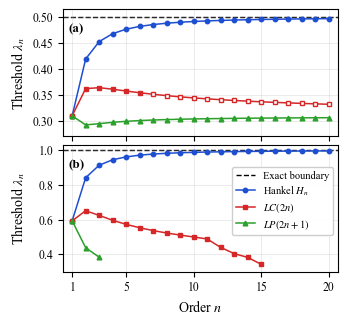

In [46]:
# Fig. 1: thresholds versus order
mpl.rcParams.update({'font.size':9,'axes.labelsize':10,'legend.fontsize':7.5,'xtick.labelsize':8.5,'ytick.labelsize':8.5})
thr  =lambda D: {n:v[0][1] for n,v in D.items() if v and v[0][0]<1e-6 and n<=20}   # detection set starts at lambda=0
inner=lambda D: {n:v[0][1] for n,v in D.items() if v and v[0][0]>1e-6}             # upper end of an inner detection interval
fig,axs=plt.subplots(2,1,figsize=(3.4,3.05))
for ax,(H,LP,LC,bd,lab,yl) in zip(axs,[(fockH,fockLP,fockLC,0.5,'(a)',(0.27,0.515)),(catH,catLP,catLC,0.99966,'(b)',(0.30,1.03))]):
    h,lp,lc,lcu=thr(H),thr(LP),thr(LC),inner(LC)
    ax.axhline(bd,color='k',ls='--',lw=1.0,label='Exact boundary',zorder=1)
    ax.plot(list(h),list(h.values()),'-o',color=COL['blue'],ms=3.2,lw=1.1,label=r'Hankel $H_n$',zorder=3)
    ax.plot(list(lc),list(lc.values()),'-s',color=COL['red'],ms=3.0,lw=1.1,label=r'$LC(2n)$',zorder=3)
    if lcu:
        k=sorted(lcu); last=max(lc)
        ax.plot([last]+k,[lc[last]]+[lcu[n] for n in k],'-',color=COL['red'],lw=1.1,zorder=3)
        ax.plot(k,[lcu[n] for n in k],'s',mfc='white',mec=COL['red'],mew=1.0,ms=3.0,zorder=4)
    ax.plot(list(lp),list(lp.values()),'-^',color=COL['green'],ms=3.4,lw=1.1,label=r'$LP(2n+1)$',zorder=3)
    ax.set_xlim(0.3,20.7); ax.set_ylim(*yl); ax.set_xticks([1,5,10,15,20]); ax.grid(alpha=0.35,lw=0.5)
    ax.set_ylabel(r'Threshold $\lambda_n$'); ax.text(0.02,0.82,lab,transform=ax.transAxes,fontsize=9.5,fontweight='bold')
axs[0].tick_params(labelbottom=False); axs[1].set_xlabel(r'Order $n$')
axs[1].legend(loc='center right',bbox_to_anchor=(1.0,0.56),framealpha=0.95,ncol=1,handlelength=1.8,labelspacing=0.3,borderpad=0.35)
fig.subplots_adjust(left=0.165,right=0.975,top=0.985,bottom=0.125,hspace=0.07); fig.align_ylabels(axs)
fig.savefig('figs/thresholds_vs_order.pdf'); plt.show()

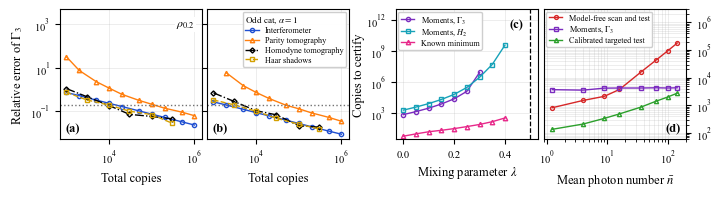

In [47]:
# Fig. 2: benchmark (estimation, certification, displacement search); every curve has its own color
_rc=dict(mpl.rcParams); mpl.rcParams.update({'font.size':8.5,'axes.labelsize':9,'legend.fontsize':6.0,'xtick.labelsize':7.6,'ytick.labelsize':7.6,'lines.markerfacecolor':'none','lines.markeredgewidth':1.0})
C2=dict(interf='#1f4fd1',tomo='#ff7f0e',shadow='#d4a000',G3='#7b2cbf',H2='#17a2b8',known='#e7298a',fsearch='#d62728',fmom='#8c564b',csearch='#2ca02c',cmom='#4d4d4d')
leg=dict(framealpha=0.95,handlelength=1.6,borderpad=0.3,labelspacing=0.22,borderaxespad=0.3)
FW,FH=7.05,1.78; W_,H_,B_=1.42,1.30,0.40
fig=plt.figure(figsize=(FW,FH)); Ax=lambda x0,**kw: fig.add_axes([x0/FW,B_/FH,W_/FW,H_/FH],**kw)
ax0=Ax(0.50); ax1=Ax(0.50+W_+0.05,sharey=ax0)
for ax,key,lab,tag in [(ax0,'fock','(a)',r'$\rho_{0.2}$'),(ax1,'cat1','(b)',r'Odd cat, $\alpha=1$')]:
    R=shadcmp[key]
    for k,c,mk,l,ls,ms in [('interf',C2['interf'],'o','Interferometer','-',3),('tomo',C2['tomo'],'^','Parity tomography','-',3.2),('homo','#000000','D','Homodyne tomography','-.',2.6),('shadow',C2['shadow'],'s','Haar shadows','--',2.8)]:
        D=homcmp[key] if k=='homo' else R[k]; x=sorted(D); ax.loglog(x,[D[v] for v in x],ls,marker=mk,color=c,ms=ms,lw=1,label=l)
    ax.axhline(0.2,color='0.45',ls=':',lw=1.0); ax.grid(alpha=0.35,which='both',lw=0.45); ax.set_xlabel('Total copies'); ax.set_ylim(5e-3,5e3); ax.set_xlim(7e2,1.5e6)
    ax.text(0.04,0.06,lab,transform=ax.transAxes,fontsize=9,fontweight='bold')
    if key=='fock': ax.text(0.95,0.93,tag,transform=ax.transAxes,ha='right',va='top',fontsize=8.5,bbox=dict(facecolor='white',edgecolor='none',pad=1.2))
ax0.set_ylabel(r'Relative error of $\Gamma_3$'); plt.setp(ax1.get_yticklabels(),visible=False)
lg=ax1.legend(*ax0.get_legend_handles_labels(),loc='upper right',title=r'Odd cat, $\alpha=1$',title_fontsize=6.6,**leg); lg._legend_box.align='left'
ax2=Ax(0.50+2*W_+0.52); fin=[r for r in cert if np.isfinite(r['Gamma3'])]; fh=[r for r in cert if np.isfinite(r['H2'])]
ax2.semilogy([r['lam'] for r in fin],[r['Gamma3'] for r in fin],'-o',color=C2['G3'],ms=3,lw=1,label=r'Moments, $\Gamma_3$')
ax2.semilogy([r['lam'] for r in fh],[r['H2'] for r in fh],'-s',color=C2['H2'],ms=2.8,lw=1,label=r'Moments, $H_2$')
ax2.semilogy([r['lam'] for r in cert],[exact_point_cost(2*r['lam']-1) for r in cert],'-^',color=C2['known'],ms=3.2,lw=1,label='Known minimum')
ax2.axvline(0.5,color='k',ls='--',lw=0.9); ax2.set_xlabel(r'Mixing parameter $\lambda$'); ax2.set_ylabel('Copies to certify',labelpad=1)
ax2.set_xlim(-0.03,0.53); ax2.set_ylim(3,1e13); ax2.grid(alpha=0.35,which='both',lw=0.45); ax2.legend(loc='upper left',**leg)
ax2.text(0.80,0.86,'(c)',transform=ax2.transAxes,fontsize=9,fontweight='bold')
ax3=Ax(0.50+3*W_+0.58); ks=sorted(adapt['moment']); nbs=[adapt['nbar'][a] for a in ks]
ax3.loglog(nbs,[adapt['modelfree'][a][0] for a in ks],'-o',color='#d62728',ms=2.8,lw=1,label='Model-free scan and test')
ax3.loglog(nbs,[adapt['moment'][a] for a in ks],'-s',color=C2['G3'],ms=2.8,lw=1,label=r'Moments, $\Gamma_3$')
ax3.loglog(nbs,[adapt['calibrated'][a][0] for a in ks],'-^',color='#2ca02c',ms=3.0,lw=1,label='Calibrated targeted test')
ax3.set_xlabel(r'Mean photon number $\bar n$'); ax3.set_ylim(60,3e6); ax3.set_xlim(0.9,200); ax3.grid(alpha=0.35,which='both',lw=0.45)
ax3.yaxis.tick_right(); ax3.legend(loc='upper left',**leg); ax3.text(0.86,0.06,'(d)',transform=ax3.transAxes,fontsize=9,fontweight='bold')
fig.savefig('figs/benchmark_combined.pdf'); plt.show(); mpl.rcParams.update(_rc)

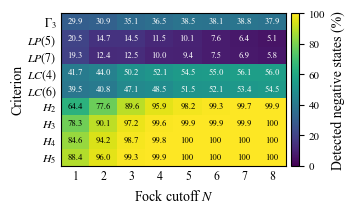

In [48]:
# Fig. 3: random-state heatmap; percentages truncated to one decimal, 100 only when every negative state is detected
mpl.rcParams.update({'font.size':9,'axes.labelsize':10,'xtick.labelsize':8.5,'ytick.labelsize':8.5})
rows=[('G3',r'$\Gamma_3$'),('LP5',r'$LP(5)$'),('LP7',r'$LP(7)$'),('LC4',r'$LC(4)$'),('LC6',r'$LC(6)$'),('H2',r'$H_2$'),('H3',r'$H_3$'),('H4',r'$H_4$'),('H5',r'$H_5$')]
Ns=sorted(heat); data=np.array([[100*heat[N][k+'_ofneg'] for N in Ns] for k,_ in rows])
fig,ax=plt.subplots(figsize=(3.4,2.0)); im=ax.imshow(data,cmap='viridis',aspect='auto',vmin=0,vmax=100)
ax.set_xticks(range(len(Ns))); ax.set_xticklabels(Ns); ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[1] for r in rows]); ax.tick_params(length=0)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v=data[i,j]; ax.text(j,i,'100' if v==100 else f'{np.floor(v*10)/10:.1f}',ha='center',va='center',fontsize=6.3,color='white' if v<60 else 'black')
ax.set_xlabel(r'Fock cutoff $N$'); ax.set_ylabel('Criterion',labelpad=2)
cb=fig.colorbar(im,ax=ax,pad=0.02,fraction=0.06); cb.set_label('Detected negative states (%)'); cb.ax.tick_params(labelsize=8)
fig.tight_layout(pad=0.25); fig.savefig('figs/random_state_detection_heatmap.pdf'); plt.show()

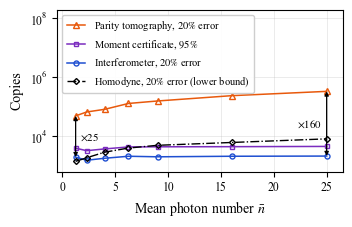

In [49]:
# Fig. 4 (End Matter): energy scaling
mpl.rcParams.update({'lines.markerfacecolor':'none','lines.markeredgewidth':1.0})
ks=sorted(scaling); nb=[scaling[k]['nbar'] for k in ks]
fig,ax=plt.subplots(figsize=(3.4,2.15))
ax.semilogy(nb,[scaling[k]['N20_tomo'] for k in ks],'-^',color=COL['orange'],ms=3.8,lw=1.1,label=r'Parity tomography, $20\%$ error')
ax.semilogy(nb,[scaling[k]['Ncert_moment'] for k in ks],'-s',color=COL['purple'],ms=3.4,lw=1.1,label=r'Moment certificate, $95\%$')
ax.semilogy(nb,[scaling[k]['N20_interf'] for k in ks],'-o',color=COL['blue'],ms=3.6,lw=1.1,label=r'Interferometer, $20\%$ error')
kh=[k for k in ks if k in hom_energy]; ax.semilogy([scaling[k]['nbar'] for k in kh],[hom_energy[k] for k in kh],'-.D',color='#000000',ms=3.0,lw=1.0,label=r'Homodyne, $20\%$ error (lower bound)')
for k,ha,dx in [(ks[0],'left',0.45),(ks[-1],'right',-0.45)]:   # arrows from the interferometer (blue) to tomography (orange)
    x=scaling[k]['nbar']; lo=scaling[k]['N20_interf']; hi=scaling[k]['N20_tomo']
    ax.annotate('',xy=(x,hi),xytext=(x,lo),arrowprops=dict(arrowstyle='<|-|>',lw=0.9,color='k',shrinkA=0,shrinkB=0,mutation_scale=6),zorder=6)
    ax.text(x+dx,(lo*hi)**0.5,rf'$\times{hi/lo:.0f}$',fontsize=7.8,ha=ha,va='center')
ax.set_xlabel(r'Mean photon number $\bar n$'); ax.set_ylabel('Copies'); ax.set_ylim(6e2,2e8); ax.set_xlim(-0.5,max(nb)+1.5)
ax.grid(alpha=0.35,which='both',lw=0.5); ax.legend(loc='upper left',framealpha=0.95,handlelength=1.8)
fig.tight_layout(pad=0.3); fig.savefig('figs/energy_scaling.pdf'); plt.show()
mpl.rcParams.update({'lines.markerfacecolor':'auto'})

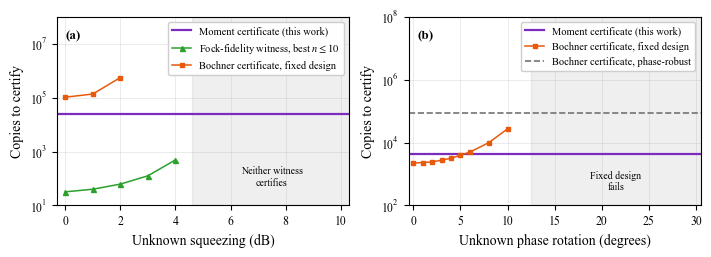

In [50]:
# SM Fig.: comparison with related works
fig,axs=plt.subplots(1,2,figsize=(7.0,2.45))
ax=axs[0]; ax.axhline(moment_cost['fock'],color=COL['purple'],lw=1.6,label='Moment certificate (this work)')
fs=[r for r in fid_sq if np.isfinite(r['cost'])]; ax.semilogy([r['dB'] for r in fs],[r['cost'] for r in fs],'-^',color=COL['green'],ms=3.6,lw=1.1,label=r'Fock-fidelity witness, best $n\leq10$')
fb=[(d,c) for d,c in bo['fock_squeeze'] if np.isfinite(c)]; ax.semilogy([d for d,c in fb],[c for d,c in fb],'-s',color=COL['orange'],ms=3.4,lw=1.1,label='Bochner certificate, fixed design')
ax.axvspan(4.6,10.5,color='0.5',alpha=0.12); ax.text(7.5,1.2e2,'Neither witness\ncertifies',ha='center',va='center',fontsize=7.2)
ax.set_xlabel('Unknown squeezing (dB)'); ax.set_ylabel('Copies to certify'); ax.set_xlim(-0.3,10.3); ax.set_ylim(10,1e8)
ax.grid(alpha=0.35,which='both',lw=0.5); ax.legend(loc='upper right',framealpha=0.95,handlelength=1.8); ax.text(0.03,0.88,'(a)',transform=ax.transAxes,fontsize=9.5,fontweight='bold')
ax=axs[1]; ax.axhline(moment_cost['cat'],color=COL['purple'],lw=1.6,label='Moment certificate (this work)')
cr=[(d,c) for d,c in bo['cat_rotation'] if np.isfinite(c)]; ax.semilogy([d for d,c in cr],[c for d,c in cr],'-s',color=COL['orange'],ms=3.4,lw=1.1,label='Bochner certificate, fixed design')
ax.axhline(bo['cat_phase_robust'],color='0.45',ls='--',lw=1.2,label='Bochner certificate, phase-robust')
ax.axvspan(12.5,30.5,color='0.5',alpha=0.12); ax.text(21.5,6e2,'Fixed design\nfails',ha='center',va='center',fontsize=7.2)
ax.set_xlabel('Unknown phase rotation (degrees)'); ax.set_ylabel('Copies to certify'); ax.set_xlim(-0.5,30.5); ax.set_ylim(1e2,1e8)
ax.grid(alpha=0.35,which='both',lw=0.5); ax.legend(loc='upper right',framealpha=0.95,handlelength=1.8); ax.text(0.03,0.88,'(b)',transform=ax.transAxes,fontsize=9.5,fontweight='bold')
fig.tight_layout(pad=0.3,w_pad=1.0); fig.savefig('figs/related_works.pdf'); plt.show()

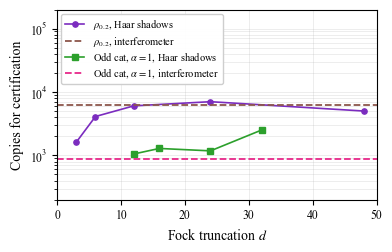

In [51]:
# SM Fig.: cost of Haar-shadow certification versus the Fock truncation (the estimation curves are Fig. 2(a, b))
mpl.rcParams.update({'font.size':9,'axes.labelsize':10,'legend.fontsize':7.5,'xtick.labelsize':8.5,'ytick.labelsize':8.5})
fig,ax=plt.subplots(figsize=(3.8,2.4))
for key,cs,cp,mk,l in [('fock','#7b2cbf','#8c564b','o',r'$\rho_{0.2}$'),('cat1','#2ca02c','#e7298a','s',r'Odd cat, $\alpha=1$')]:
    ds=sorted(k for k in shadow_d[key] if k!='parity')
    ax.semilogy(ds,[shadow_d[key][d] for d in ds],'-'+mk,color=cs,ms=3.8,lw=1.2,label=l+', Haar shadows')
    ax.axhline(shadow_d[key]['parity'],color=cp,ls='--',lw=1.3,label=l+', interferometer')
ax.set_xlabel(r'Fock truncation $d$'); ax.set_ylabel('Copies for certification'); ax.grid(alpha=0.35,which='both',lw=0.45)
ax.set_xlim(0,50); ax.set_ylim(2e2,2e5); ax.legend(loc='upper left',ncol=1,framealpha=0.95,handlelength=1.8,labelspacing=0.25,borderaxespad=0.4)
fig.tight_layout(pad=0.3); fig.savefig('figs/shadow_truncation.pdf'); plt.show()

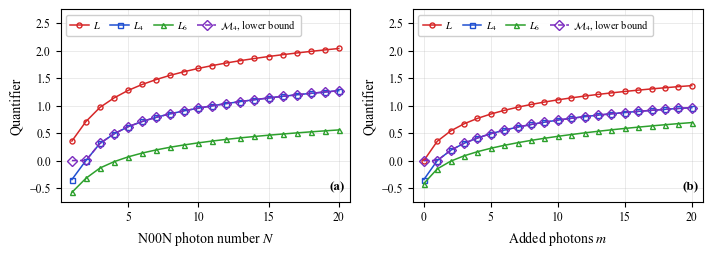

total run time: 188.2 minutes


In [52]:
# SM Fig. 1: N00N and photon-added coherent states (one PDF, two panels)
mpl.rcParams.update({'font.size':9,'axes.labelsize':10,'legend.fontsize':7.5,'xtick.labelsize':8.5,'ytick.labelsize':8.5,'lines.markerfacecolor':'none','lines.markeredgewidth':1.0})
fig,axs=plt.subplots(1,2,figsize=(7.0,2.45))
for ax,key,xl,lab in [(axs[0],'noon','N00N photon number $N$','(a)'),(axs[1],'pacs','Added photons $m$','(b)')]:
    rr=noonpacs[key]; x=[r.get('N',r.get('m')) for r in rr]
    for q,c,mk,l in [('L','#d62728','o',r'$L$'),('L4','#1f4fd1','s',r'$L_4$'),('L6','#2ca02c','^',r'$L_6$')]:
        ax.plot(x,[r[q] for r in rr],'-'+mk,color=c,ms=3.6,lw=1.1,label=l)
    ax.plot(x,[r['M4lb'] for r in rr],'--D',color='#7b2cbf',ms=5.2,lw=1.1,label=r'$\mathcal{M}_4$, lower bound')
    ax.set_xlabel(xl); ax.set_ylabel('Quantifier'); ax.grid(alpha=0.35,lw=0.5); ax.set_xlim(-0.8 if key=='pacs' else 0.2,max(x)+0.8); ax.set_ylim(-0.75,2.75)
    ax.legend(loc='upper left',framealpha=0.95,handlelength=1.8,labelspacing=0.25,ncol=4,columnspacing=0.9,handletextpad=0.4)
    ax.text(0.93,0.06,lab,transform=ax.transAxes,fontsize=9.5,fontweight='bold')
fig.tight_layout(pad=0.3,w_pad=1.0); fig.savefig('figs/noon_pacs.pdf'); plt.show()
mpl.rcParams.update({'lines.markerfacecolor':'auto'})
print('total run time: %.1f minutes'%((time.time()-t_start)/60))